In [2]:
# Imports and settings
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

TARGET_WIDTH = 800        # all analysis runs at this width, so thresholds mean the same on every photo

In [3]:
uploaded = files.upload()                 # choose one image in the dialog
path = next(iter(uploaded))               # filename of the uploaded image
print("Loaded file:", path)

Saving test pic brightness.jpg to test pic brightness.jpg
Loaded file: test pic brightness.jpg


In [4]:
#loader with checks

def load_image(path):
    img = cv2.imread(path, cv2.IMREAD_COLOR)         # IMREAD_COLOR forces 3 channels, so PNGs with alpha or grayscale files still work
    if img is None:                                  # imread fails silently, so check explicitly
        raise FileNotFoundError(f"Could not read image: {path}")
    return img                                       # BGR, uint8, shape (H, W, 3)

In [5]:
#prepare function
def prepare(img_bgr, target_width=TARGET_WIDTH):
    h, w = img_bgr.shape[:2]                         # shape is (height, width)
    scale = min(1.0, target_width / w)               # shrink big images, never enlarge small ones (enlarging invents detail)
    if scale < 1.0:
        new_size = (target_width, int(round(h * scale)))                          # (width, height), ratio preserved
        small = cv2.resize(img_bgr, new_size, interpolation=cv2.INTER_AREA)       # INTER_AREA is best for shrinking
    else:
        small = img_bgr.copy()                       # copy so later fixes never touch the original
    return {
        "bgr":  small,                                                   # OpenCV working copy
        "rgb":  cv2.cvtColor(small, cv2.COLOR_BGR2RGB),                  # for Matplotlib display
        "gray": cv2.cvtColor(small, cv2.COLOR_BGR2GRAY),                 # for most quality checks
        "scale": scale,                                                  # remembered so results can be mapped back to full size
        "orig_size": (w, h),
    }

Original size (W x H): (596, 335)
Prepared size (W x H): 596 x 335
Scale factor: 1.0
dtype: uint8 | gray shape: (335, 596)


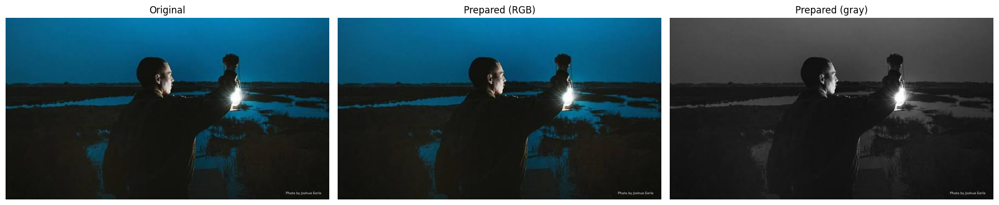

In [6]:
# verification
original = load_image(path)
data = prepare(original)

print("Original size (W x H):", data["orig_size"])
print("Prepared size (W x H):", data["bgr"].shape[1], "x", data["bgr"].shape[0])
print("Scale factor:", round(data["scale"], 3))
print("dtype:", data["bgr"].dtype, "| gray shape:", data["gray"].shape)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB)); axes[0].set_title("Original")          # convert to RGB so colours are correct
axes[1].imshow(data["rgb"]);                                axes[1].set_title("Prepared (RGB)")
axes[2].imshow(data["gray"], cmap="gray", vmin=0, vmax=255); axes[2].set_title("Prepared (gray)")  # vmin/vmax stop auto-stretching
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

In [7]:
#limit
# What: loads pandas for tables and sets the limit and margin for each check in one place.
# Why: a metric is only "fail" when it is past the limit by more than the margin, so photos near the line are left alone.
import pandas as pd

LIMITS = {
    "dark_mean":   {"limit": 80,  "margin": 10},    # mean brightness below 80 = dark, clearly dark below 70
    "bright_mean": {"limit": 180, "margin": 10},    # mean brightness above 180 = bright, clearly bright above 190
    "contrast":    {"limit": 120, "margin": 15},    # 2nd-to-98th percentile range below 120 = low contrast, clear below 105
    "clipping":    {"limit": 5.0, "margin": 2.0},   # percent of pure black or white pixels above 5 = clipped, clear above 7
}

In [8]:
#measure the stats
# What: computes the numbers behind every check: mean, percentile range, histogram and the share of clipped pixels.
# Why: percentiles ignore a few extreme pixels, so one hot pixel cannot hide a washed-out image.
def exposure_stats(gray):
    hist = cv2.calcHist([gray], [0], None, [256], [0, 256]).ravel()    # pixel count for each brightness 0-255
    p2, p98 = np.percentile(gray, (2, 98))                              # robust darkest and brightest levels
    return {
        "mean": float(gray.mean()),                                     # overall brightness
        "p2": float(p2), "p98": float(p98),
        "range": float(p98 - p2),                                       # contrast measure: how spread out the tones are
        "dark_clip": float(100 * np.mean(gray <= 5)),                   # % of near-black pixels (lost shadow detail)
        "bright_clip": float(100 * np.mean(gray >= 250)),               # % of near-white pixels (lost highlight detail)
        "hist": hist,
    }

In [9]:
#judge a metric (the dead-zone rule)
# What: turns "how far past the limit is this metric" into a status (ok, borderline, fail) and a 0-100 score.
# Why: "borderline" is reported but never fixed, which is what keeps good photos untouched.
def judge(excess, margin, scale):
    if excess <= 0:
        status = "ok"                                    # within the limit
    elif excess <= margin:
        status = "borderline"                            # past the line but inside the dead zone, so no fix
    else:
        status = "fail"                                  # clearly outside, so a fix is allowed
    score = 100 * (1 - min(1.0, max(0.0, excess) / scale))   # 100 = perfect, falls to 0 at "scale" past the limit
    return status, round(score, 1)

In [10]:
# The exposure and contrast checks
# What: runs the brightness, contrast and clipping checks and returns one result row for each.
# Why: every check returns the same format (name, value, status, score, label), so later steps can add checks without changing the report code.
def check_exposure_contrast(gray):
    s = exposure_stats(gray)
    L = LIMITS
    checks = []

    # Brightness: two-sided, too dark or too bright
    dark_excess = L["dark_mean"]["limit"] - s["mean"]
    bright_excess = s["mean"] - L["bright_mean"]["limit"]
    if dark_excess > 0:
        status, score = judge(dark_excess, L["dark_mean"]["margin"], L["dark_mean"]["limit"]); label = "dark"
    elif bright_excess > 0:
        status, score = judge(bright_excess, L["bright_mean"]["margin"], 255 - L["bright_mean"]["limit"]); label = "bright"
    else:
        status, score, label = "ok", 100.0, "normal"
    checks.append({"name": "brightness", "value": round(s["mean"], 1), "status": status, "score": score, "label": label})

    # Contrast: a narrow spread of tones means a flat, washed-out look
    status, score = judge(L["contrast"]["limit"] - s["range"], L["contrast"]["margin"], L["contrast"]["limit"])
    checks.append({"name": "contrast", "value": round(s["range"], 1), "status": status, "score": score,
                   "label": "good" if status == "ok" else "low contrast"})

    # Clipping: use whichever end (shadows or highlights) is worse
    worst = max(s["dark_clip"], s["bright_clip"])
    where = "shadows" if s["dark_clip"] >= s["bright_clip"] else "highlights"
    status, score = judge(worst - L["clipping"]["limit"], L["clipping"]["margin"], 25)
    checks.append({"name": "clipping", "value": round(worst, 2), "status": status, "score": score,
                   "label": "none" if status == "ok" else f"clipped {where}"})
    return checks, s

      name  value status  score        label
brightness  43.70   fail   54.7         dark
  contrast  77.00   fail   64.2 low contrast
  clipping   0.12     ok  100.0         none


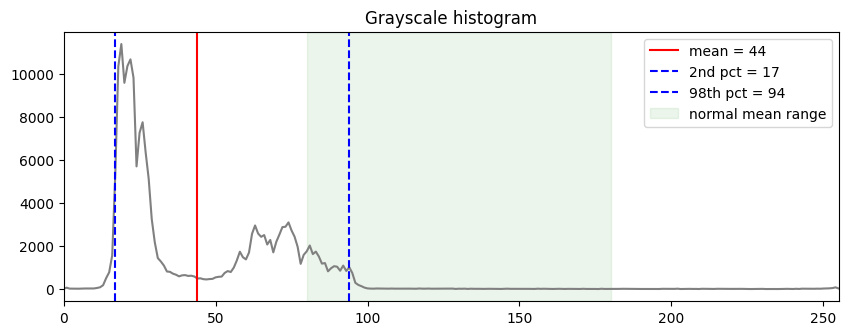

In [11]:
#Run it on your photo and plot the histogram
# What: analyses the prepared photo from step 1, prints the results as a table and draws the histogram with the limits marked.
# Why: seeing the mean and percentiles on the histogram makes it clear why each verdict was given.
checks, stats = check_exposure_contrast(data["gray"])
print(pd.DataFrame(checks).to_string(index=False))

plt.figure(figsize=(10, 3.5))
plt.plot(stats["hist"], color="gray")
plt.axvline(stats["mean"], color="red", label=f"mean = {stats['mean']:.0f}")                       # overall brightness
plt.axvline(stats["p2"],  color="blue", linestyle="--", label=f"2nd pct = {stats['p2']:.0f}")      # darkest robust level
plt.axvline(stats["p98"], color="blue", linestyle="--", label=f"98th pct = {stats['p98']:.0f}")    # brightest robust level
plt.axvspan(LIMITS["dark_mean"]["limit"], LIMITS["bright_mean"]["limit"], color="green", alpha=0.08, label="normal mean range")
plt.xlim(0, 255); plt.title("Grayscale histogram"); plt.legend(); plt.show()

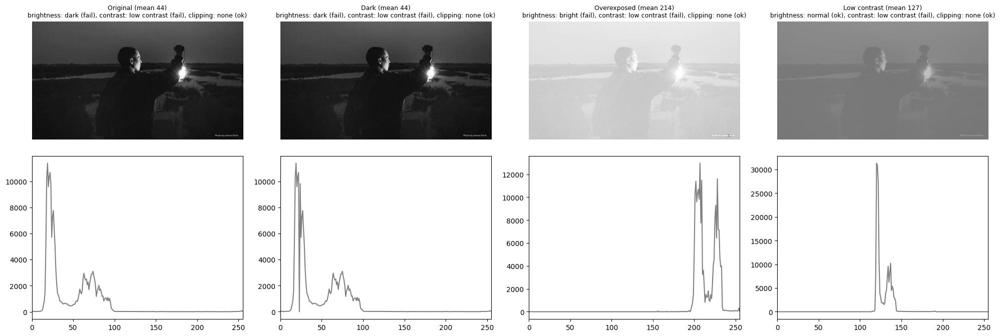

                             Original                       Dark                Overexposed               Low contrast
brightness          dark (fail, 54.7)          dark (fail, 55.5)        bright (fail, 54.1)         normal (ok, 100.0)
contrast    low contrast (fail, 64.2)  low contrast (fail, 65.0)  low contrast (fail, 27.5)  low contrast (fail, 20.0)
clipping             none (ok, 100.0)           none (ok, 100.0)           none (ok, 100.0)           none (ok, 100.0)


In [12]:
# What: makes dark, overexposed and low-contrast copies by steering each one to a target mean brightness, then runs the same checks on each.
# Why: fixed multipliers depend on the original photo, but a target mean guarantees the copy is damaged by the same amount every time.
def set_mean(gray, target):
    g = gray.astype(np.float32) / 255.0
    lo, hi = 0.05, 20.0                                    # search range for gamma
    for _ in range(40):                                    # bisection: the mean falls as gamma rises, so we can home in on the target
        gamma = (lo + hi) / 2
        mean = (g ** gamma).mean() * 255
        if mean > target: lo = gamma                       # still too bright, so raise gamma
        else: hi = gamma                                   # too dark, so lower gamma
    return np.clip(255 * g ** gamma, 0, 255).astype(np.uint8)

g = data["gray"].astype(np.float32)
test_images = {
    "Original":      data["gray"],
    "Dark":          set_mean(data["gray"], 45),                                     # mean forced to about 45 (limit is 80)
    "Overexposed":   set_mean(data["gray"], 215),                                    # mean forced to about 215 (limit is 180)
    "Low contrast":  np.clip(128 + (g - g.mean()) * 0.3, 0, 255).astype(np.uint8),   # keeps mean near 128 but shrinks the tonal spread to 30%
}

results = {}
fig, axes = plt.subplots(2, 4, figsize=(20, 7))
for j, (name, img) in enumerate(test_images.items()):
    res, st = check_exposure_contrast(img)
    results[name] = {c["name"]: c for c in res}
    axes[0, j].imshow(img, cmap="gray", vmin=0, vmax=255); axes[0, j].axis("off")      # vmin/vmax so display is not auto-stretched
    axes[0, j].set_title(f"{name} (mean {img.mean():.0f})\n" + ", ".join(f"{c['name']}: {c['label']} ({c['status']})" for c in res), fontsize=9)
    axes[1, j].plot(st["hist"], color="gray"); axes[1, j].set_xlim(0, 255)
plt.tight_layout(); plt.show()

summary = pd.DataFrame({name: {k: f"{v['label']} ({v['status']}, {v['score']})" for k, v in r.items()}
                        for name, r in results.items()})
print(summary.to_string())

# Exposure and contrast analysis and fixes


In [14]:
#settings and color helper
# What: sets the target brightness for each fix, the allowed gamma range, the check weights and the minimum score gain to accept a fix.
# Why: keeping every tunable number in one place makes the tool easy to adjust after you have tested it on more photos.
TARGET_MEAN = {"dark": 100, "bright": 150}              # a dark photo is lifted to mean ~100, a bright one pulled down to ~150
GAMMA_RANGE = (0.4, 2.5)                                # limits stop extreme gamma from wrecking the image
STRETCH_PCT = (2, 98)                                   # percentiles used as the "darkest" and "brightest" levels
STRETCH_OUT = (10, 245)                                 # stretched tones are mapped here, leaving headroom so nothing clips
WEIGHTS = {"brightness": 0.4, "contrast": 0.4, "clipping": 0.2}   # exposure and contrast matter most
MIN_GAIN = 1.0                                          # a fix must raise the overall score by at least this much to be kept

In [15]:
# Analyse an image and compute the overall score
# What: wraps the step 2 checks into one function that also returns a weighted overall score from 0 to 100.
# Why: the overall score is the single number the guard compares before and after a fix.
def analyze(bgr):
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)                       # the checks measure brightness, so use grayscale
    checks, stats = check_exposure_contrast(gray)                      # reuse the step 2 function
    by_name = {c["name"]: c for c in checks}
    overall = sum(WEIGHTS[n] * by_name[n]["score"] for n in WEIGHTS) / sum(WEIGHTS.values())   # weighted average of check scores
    return {"checks": checks, "by_name": by_name, "overall": round(overall, 1), "stats": stats}

In [16]:
# Brightness fix (automatic gamma)
# What: finds the gamma that moves the mean lightness to the target, then applies it to the L channel only.
# Why: gamma lifts shadows without blowing out highlights, and changing only L keeps the colours the same.
def fix_brightness(bgr, direction):
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
    L = lab[..., 0]                                                    # lightness channel, 0-255
    hist = np.bincount(L.ravel(), minlength=256).astype(np.float64)    # histogram lets us predict the new mean without touching the image
    x = np.arange(256) / 255.0
    target = TARGET_MEAN[direction]
    lo, hi = GAMMA_RANGE
    for _ in range(40):                                                # bisection: mean falls as gamma rises
        g = (lo + hi) / 2
        mean = (hist * 255 * x ** g).sum() / hist.sum()
        if mean > target: lo = g                                       # still too bright, so raise gamma
        else: hi = g                                                   # too dark, so lower gamma
    gamma = float(np.clip((lo + hi) / 2, *GAMMA_RANGE))
    lut = np.clip(255 * x ** gamma, 0, 255).astype(np.uint8)           # lookup table: new value for each old value
    lab[..., 0] = cv2.LUT(L, lut)
    return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR), {"gamma": round(gamma, 3)}

In [17]:
# Contrast fixes (stretch, then CLAHE)
# What: stretch spreads the 2nd-98th percentile range over almost the full scale; CLAHE adds local contrast on small tiles.
# Why: the stretch is predictable and gentle, so CLAHE is kept as a second option because it can amplify noise.
def fix_stretch(bgr):
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
    L = lab[..., 0].astype(np.float32)
    lo, hi = np.percentile(L, STRETCH_PCT)
    if hi - lo < 5:                                                    # a nearly flat image cannot be stretched safely
        return bgr, {"stretch": "skipped"}
    out = (L - lo) * (STRETCH_OUT[1] - STRETCH_OUT[0]) / (hi - lo) + STRETCH_OUT[0]
    lab[..., 0] = np.clip(out, 0, 255).astype(np.uint8)
    return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR), {"stretch_from": (round(float(lo), 1), round(float(hi), 1))}

def fix_clahe(bgr, clip=2.0, tiles=(8, 8)):
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=clip, tileGridSize=tiles).apply(lab[..., 0])   # equalise each tile, limit the gain with clip
    return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR), {"clahe_clip": clip}

In [18]:
# the pipeline with the guard
# What: runs the fixes only for failing checks, re-measures after each one, and keeps the original if the result is not a clear improvement.
# Why: this guard is what stops the tool from "fixing" a good photo or making one problem worse while fixing another.
def run_exposure_contrast(bgr):
    before = analyze(bgr)
    cur, applied, params = bgr.copy(), [], {}

    if before["by_name"]["brightness"]["status"] == "fail":            # only a clear brightness failure triggers gamma
        cur, p = fix_brightness(cur, before["by_name"]["brightness"]["label"])
        applied.append("gamma"); params.update(p)

    if analyze(cur)["by_name"]["contrast"]["status"] == "fail":        # re-check, because gamma alone may already have fixed contrast
        cur, p = fix_stretch(cur)
        applied.append("stretch"); params.update(p)
        if analyze(cur)["by_name"]["contrast"]["status"] == "fail":   # CLAHE only if the stretch was not enough
            cur, p = fix_clahe(cur)
            applied.append("clahe"); params.update(p)

    after = analyze(cur)
    gain = after["overall"] - before["overall"]
    regressed = [n for n in WEIGHTS if before["by_name"][n]["status"] != "fail" and after["by_name"][n]["status"] == "fail"]
    if applied and (gain < MIN_GAIN or regressed):                     # not a clear win, so undo everything
        reason = f"rejected (gain {gain:.1f}" + (f", regressed: {regressed}" if regressed else "") + ")"
        return {"image": bgr, "before": before, "after": before, "applied": [], "params": {}, "accepted": False, "reason": reason}
    return {"image": cur, "before": before, "after": after, "applied": applied, "params": params, "accepted": bool(applied),
            "reason": "no fix needed" if not applied else f"accepted (gain {gain:.1f})"}

Applied: ['gamma'] | Params: {'gamma': 0.533} | accepted (gain 28.7)
Overall score: 67.6 -> 96.3
     check      before              after
brightness 43.7 (fail)          90.3 (ok)
  contrast 77.0 (fail) 109.0 (borderline)
  clipping   0.12 (ok)          0.15 (ok)


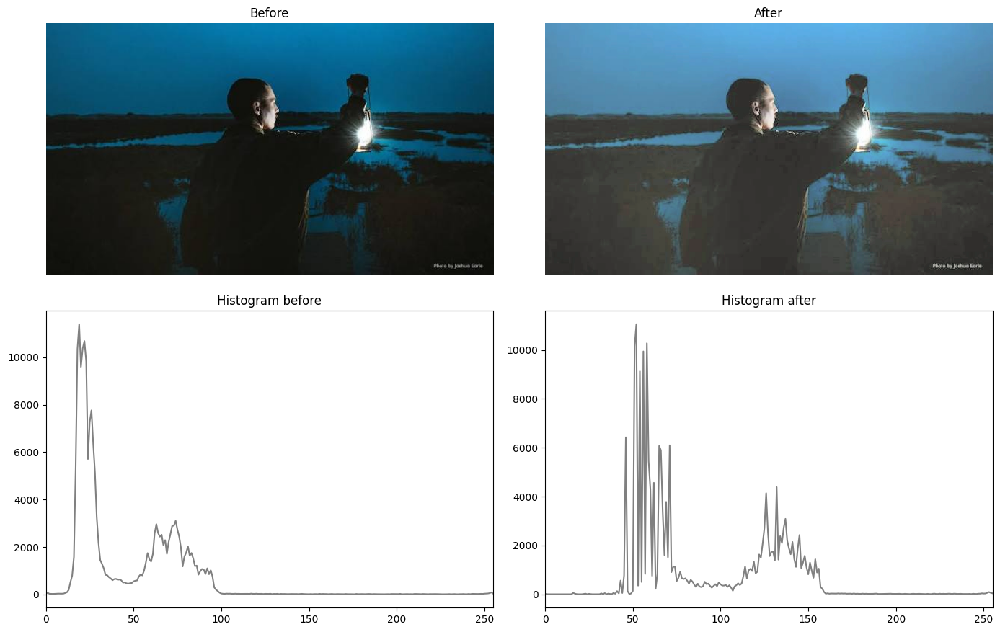

In [19]:
# Run on my photo
# What: runs the pipeline on the prepared photo, then shows before and after with histograms and a table of every check.
# Why: the histogram should spread out and the table should show the failing checks improving, which is the step 3 test.
res = run_exposure_contrast(data["bgr"])
print("Applied:", res["applied"], "| Params:", res["params"], "|", res["reason"])
print("Overall score:", res["before"]["overall"], "->", res["after"]["overall"])

rows = []
for name in WEIGHTS:
    b, a = res["before"]["by_name"][name], res["after"]["by_name"][name]
    rows.append({"check": name, "before": f"{b['value']} ({b['status']})", "after": f"{a['value']} ({a['status']})"})
print(pd.DataFrame(rows).to_string(index=False))

fixed_gray = cv2.cvtColor(res["image"], cv2.COLOR_BGR2GRAY)
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes[0, 0].imshow(data["rgb"]); axes[0, 0].set_title("Before"); axes[0, 0].axis("off")
axes[0, 1].imshow(cv2.cvtColor(res["image"], cv2.COLOR_BGR2RGB)); axes[0, 1].set_title("After"); axes[0, 1].axis("off")
axes[1, 0].plot(res["before"]["stats"]["hist"], color="gray"); axes[1, 0].set_xlim(0, 255); axes[1, 0].set_title("Histogram before")
axes[1, 1].plot(res["after"]["stats"]["hist"], color="gray"); axes[1, 1].set_xlim(0, 255); axes[1, 1].set_title("Histogram after")
plt.tight_layout(); plt.show()

In [20]:
# Tests on damaged copies and on an already-fixed image
# What: runs the pipeline on the dark, overexposed and low-contrast copies from step 2, then runs it a second time on your fixed photo.
# Why: damaged copies should improve, and the second run on a fixed photo should change almost nothing, which proves it leaves good images alone.
for name in ["Dark", "Overexposed", "Low contrast"]:
    bgr = cv2.cvtColor(test_images[name], cv2.COLOR_GRAY2BGR)           # step 2 copies are grayscale, so convert to 3 channels
    r = run_exposure_contrast(bgr)
    print(f"{name:13s} score {r['before']['overall']:5.1f} -> {r['after']['overall']:5.1f} | applied {r['applied']} | {r['reason']}")

second = run_exposure_contrast(res["image"])                            # run again on the already-fixed photo
diff = cv2.absdiff(second["image"], res["image"]).mean()
print(f"\nSecond pass on fixed photo: applied {second['applied']} | {second['reason']} | mean pixel change {diff:.2f}")

Dark          score  68.2 -> 100.0 | applied ['gamma', 'stretch'] | accepted (gain 31.8)
Overexposed   score  52.6 -> 100.0 | applied ['gamma', 'stretch'] | accepted (gain 47.4)
Low contrast  score  68.0 -> 100.0 | applied ['stretch'] | accepted (gain 32.0)

Second pass on fixed photo: applied [] | no fix needed | mean pixel change 0.00


# Blur and Noise Fixes and Analysis

In [22]:
# What: adds the blur and noise limits to the same LIMITS dictionary and defines weights for the full overall score.
# Why: one place for every tunable number, and the weights now cover all five checks so the score reflects blur and noise too.
LIMITS["blur"]  = {"limit": 60,  "margin": 20}     # sharpness below 60 = soft, clearly blurry below 40
LIMITS["noise"] = {"limit": 4.0, "margin": 1.5}    # noise sigma above 4 grey levels = noisy, clearly noisy above 5.5
WEIGHTS_ALL = {"brightness": 0.25, "contrast": 0.25, "clipping": 0.10, "blur": 0.25, "noise": 0.15}

In [23]:
# Noise estimate
# What: estimates the noise standard deviation in grey levels from a kernel that cancels smooth image content, using only flat pixels.
# Why: edges and texture would be counted as noise, so we measure only the flattest 40% of pixels and skip clipped black and white ones.
def noise_stats(gray):
    g = gray.astype(np.float32)
    kernel = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float32)       # Immerkaer kernel: near zero on smooth areas, responds to noise
    resp = np.abs(cv2.filter2D(g, -1, kernel))
    sm = cv2.GaussianBlur(g, (5, 5), 1.5)                                       # smooth first so the gradient reflects structure, not noise
    grad = np.hypot(cv2.Sobel(sm, cv2.CV_32F, 1, 0), cv2.Sobel(sm, cv2.CV_32F, 0, 1))
    mask = (grad < np.percentile(grad, 40)) & (g > 5) & (g < 250)               # flat and not clipped
    if mask.sum() < 500:                                                        # too few usable pixels for a reliable estimate
        return {"sigma": 0.0, "mask": mask}
    sigma = np.sqrt(np.pi / 2) * resp[mask].mean() / 6                          # converts the mean kernel response to a sigma
    return {"sigma": float(sigma), "mask": mask}

In [24]:
# What: measures sharpness as the Laplacian variance of each tile, subtracts what the estimated noise would add, and takes the 90th percentile.
# Why: the percentile means a sharp subject on a soft background still passes, and the subtraction stops noise from making a blurry photo look sharp.
def laplacian_noise_floor(sigma):
    field = np.random.default_rng(0).normal(0, max(sigma, 1e-6), (256, 256)).astype(np.float32)   # synthetic noise with the estimated sigma
    lap = cv2.Laplacian(cv2.GaussianBlur(field, (3, 3), 0), cv2.CV_32F, ksize=3)                  # CV_32F output: float32 input cannot be written to CV_64F
    return float(lap.var())                                                                       # same pipeline as the real image, so same inflation

def blur_stats(gray, noise_sigma, grid=(4, 4)):
    lap = cv2.Laplacian(cv2.GaussianBlur(gray, (3, 3), 0), cv2.CV_64F, ksize=3)   # 8-bit input to CV_64F is supported, so this line is unchanged
    h, w = lap.shape; gh, gw = grid
    tiles = np.array([[lap[i*h//gh:(i+1)*h//gh, j*w//gw:(j+1)*w//gw].var() for j in range(gw)] for i in range(gh)])
    floor = laplacian_noise_floor(noise_sigma)
    tiles = np.maximum(tiles - floor, 0)                                          # remove the part explained by noise
    return {"sharpness": float(np.percentile(tiles, 90)), "tiles": tiles, "noise_floor": floor}

In [25]:
# The checks and the full analysis
# What: turns the blur and noise numbers into check rows in the same format as step 2, then combines all five checks into one overall score.
# Why: the same row format means the report and the guard from step 3 work unchanged when we add new checks.
def check_blur_noise(gray):
    nst = noise_stats(gray)
    bst = blur_stats(gray, nst["sigma"])                                           # noise first, because the blur score needs it
    B, N = LIMITS["blur"], LIMITS["noise"]
    b_status, b_score = judge(B["limit"] - bst["sharpness"], B["margin"], B["limit"])
    n_status, n_score = judge(nst["sigma"] - N["limit"], N["margin"], 15)
    b_label = {"ok": "sharp", "borderline": "slightly soft", "fail": "blurry"}[b_status]
    n_label = {"ok": "clean", "borderline": "slightly noisy", "fail": "noisy"}[n_status]
    checks = [{"name": "blur",  "value": round(bst["sharpness"], 1), "status": b_status, "score": b_score, "label": b_label},
              {"name": "noise", "value": round(nst["sigma"], 2),     "status": n_status, "score": n_score, "label": n_label}]
    return checks, bst, nst

def analyze_all(bgr):
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    ex, ex_stats = check_exposure_contrast(gray)
    bn, bst, nst = check_blur_noise(gray)
    by_name = {c["name"]: c for c in ex + bn}
    overall = sum(WEIGHTS_ALL[n] * by_name[n]["score"] for n in WEIGHTS_ALL) / sum(WEIGHTS_ALL.values())
    return {"checks": ex + bn, "by_name": by_name, "overall": round(overall, 1), "stats": ex_stats, "blur": bst, "noise": nst}

     check            original         after step 3
brightness         43.7 (dark)        90.3 (normal)
  contrast 77.0 (low contrast) 109.0 (low contrast)
  clipping         0.12 (none)          0.15 (none)
      blur       529.1 (sharp)        756.9 (sharp)
     noise        0.06 (clean)         0.09 (clean)
Overall: 79.7 -> 97.7


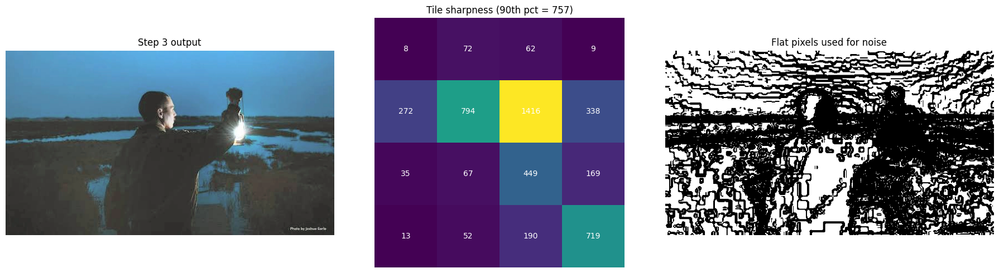

In [26]:
# Run on your photo and see how the estimates work
# What: analyses your original and your step 3 output, then shows the tile sharpness map and the flat pixels used for the noise estimate.
# Why: comparing the two noise values shows why we measure noise after the exposure fix, and the maps show what each number is based on.
orig_a  = analyze_all(data["bgr"])
fixed_a = analyze_all(res["image"])                                    # res is the step 3 result
rows = [{"check": n, "original": f"{orig_a['by_name'][n]['value']} ({orig_a['by_name'][n]['label']})",
         "after step 3": f"{fixed_a['by_name'][n]['value']} ({fixed_a['by_name'][n]['label']})"} for n in WEIGHTS_ALL]
print(pd.DataFrame(rows).to_string(index=False))
print("Overall:", orig_a["overall"], "->", fixed_a["overall"])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].imshow(cv2.cvtColor(res["image"], cv2.COLOR_BGR2RGB)); axes[0].set_title("Step 3 output"); axes[0].axis("off")
tiles = fixed_a["blur"]["tiles"]
axes[1].imshow(tiles, cmap="viridis"); axes[1].set_title(f"Tile sharpness (90th pct = {fixed_a['blur']['sharpness']:.0f})")
for (i, j), v in np.ndenumerate(tiles): axes[1].text(j, i, f"{v:.0f}", ha="center", va="center", color="white")   # value in each tile
axes[1].axis("off")
axes[2].imshow(fixed_a["noise"]["mask"], cmap="gray"); axes[2].set_title("Flat pixels used for noise"); axes[2].axis("off")
plt.tight_layout(); plt.show()

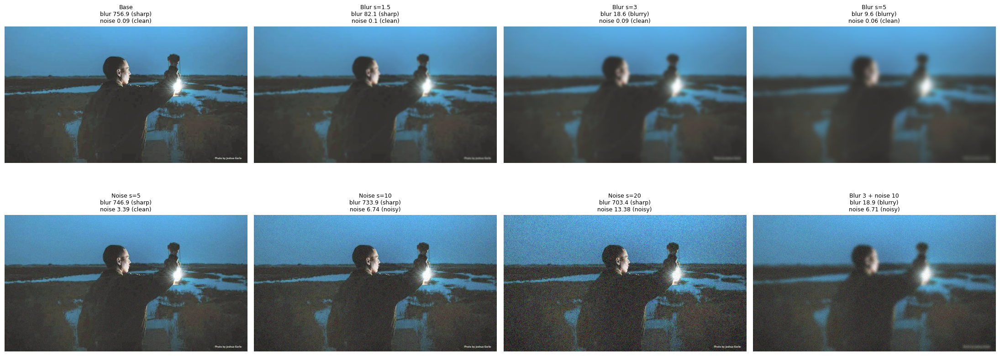

             copy  sharpness  noise_sigma blur noise  overall
             Base      756.9         0.09   ok    ok     97.7
       Blur s=1.5       82.1         0.10   ok    ok     97.7
         Blur s=3       18.6         0.09 fail    ok     80.2
         Blur s=5        9.6         0.06 fail    ok     76.3
        Noise s=5      746.9         3.39   ok    ok     98.1
       Noise s=10      733.9         6.74   ok  fail     96.6
       Noise s=20      703.4        13.38   ok  fail     90.6
Blur 3 + noise 10       18.9         6.71 fail  fail     79.1


In [27]:
# Test with damaged copies at known strength
# What: adds Gaussian blur and Gaussian noise at three strengths to your step 3 output, plus one copy with both, and measures all of them.
# Why: we know exactly how much damage each copy has, so blur scores should fall and noise scores should rise in order.
def add_noise(bgr, sigma, seed=0):
    noise = np.random.default_rng(seed).normal(0, sigma, bgr.shape)                     # same noise strength on every channel
    return np.clip(bgr.astype(np.float32) + noise, 0, 255).astype(np.uint8)

base = res["image"]
tests = {
    "Base":            base,
    "Blur s=1.5":      cv2.GaussianBlur(base, (0, 0), 1.5),
    "Blur s=3":        cv2.GaussianBlur(base, (0, 0), 3),
    "Blur s=5":        cv2.GaussianBlur(base, (0, 0), 5),
    "Noise s=5":       add_noise(base, 5),
    "Noise s=10":      add_noise(base, 10),
    "Noise s=20":      add_noise(base, 20),
    "Blur 3 + noise 10": add_noise(cv2.GaussianBlur(base, (0, 0), 3), 10),
}
out = {name: analyze_all(img) for name, img in tests.items()}

fig, axes = plt.subplots(2, 4, figsize=(22, 9))
for ax, (name, img) in zip(axes.flat, tests.items()):
    a = out[name]
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax.axis("off")
    ax.set_title(f"{name}\nblur {a['by_name']['blur']['value']} ({a['by_name']['blur']['label']})\nnoise {a['by_name']['noise']['value']} ({a['by_name']['noise']['label']})", fontsize=9)
plt.tight_layout(); plt.show()

print(pd.DataFrame([{"copy": n, "sharpness": a["by_name"]["blur"]["value"], "noise_sigma": a["by_name"]["noise"]["value"],
                     "blur": a["by_name"]["blur"]["status"], "noise": a["by_name"]["noise"]["status"], "overall": a["overall"]}
                    for n, a in out.items()]).to_string(index=False))

In [29]:
# What: compares the true noise strength with the estimated one, and the sharpness with and without noise correction, for the blur-only and blur+noise copies.
# Why: this shows whether the estimator is wrong, the correction is wrong, or the limit is simply too low for your photo.
clean   = cv2.cvtColor(tests["Blur s=3"], cv2.COLOR_BGR2GRAY).astype(np.float32)
noisy   = cv2.cvtColor(tests["Blur 3 + noise 10"], cv2.COLOR_BGR2GRAY).astype(np.float32)
true_sigma = float((noisy - clean).std())                       # real noise in grey levels (about 6.7 for 10 per channel, because gray averages the channels)

for name in ["Blur s=3", "Blur 3 + noise 10"]:
    g = cv2.cvtColor(tests[name], cv2.COLOR_BGR2GRAY)
    est = noise_stats(g)["sigma"]
    raw = blur_stats(g, 0.0)["sharpness"]                       # sharpness with no noise correction
    corrected = blur_stats(g, est)["sharpness"]                 # sharpness with the correction used by the check
    print(f"{name:20s} estimated noise {est:5.2f} | raw sharpness {raw:6.1f} | corrected sharpness {corrected:6.1f} | status {out[name]['by_name']['blur']['status']}")
print(f"True noise sigma added: {true_sigma:.2f} | blur limit: {LIMITS['blur']['limit']}, margin: {LIMITS['blur']['margin']}")

Blur s=3             estimated noise  0.09 | raw sharpness   18.6 | corrected sharpness   18.6 | status fail
Blur 3 + noise 10    estimated noise  6.71 | raw sharpness  201.4 | corrected sharpness   18.9 | status fail
True noise sigma added: 6.70 | blur limit: 60, margin: 20


# Denoise fix

In [30]:
#settings
# What: sets the denoise strength range, the non-local-means window sizes and the share of impulse pixels that counts as salt-and-pepper noise.
# Why: all tunable numbers stay in one place, so you can adjust them after testing on more photos.
DENOISE = {
    "h_min": 2.0, "h_max": 12.0,        # allowed filter strength in grey levels, so a bad estimate cannot erase all detail
    "template": 7, "search": 21,        # non-local means patch size and search window (OpenCV's recommended values)
    "impulse_pct": 1.0,                 # more than 1 percent isolated black or white pixels = salt-and-pepper noise
}
STRENGTHS = (1.0, 0.6)                  # try full strength first, then a gentler one if the guard rejects it

In [31]:
#detect salt and pepper noise
# What: counts pixels that are pure black or white AND very different from their 3x3 median, which is the signature of impulse noise.
# Why: the Gaussian-noise estimator from step 4 ignores black and white pixels, so it cannot see this kind of noise and needs a separate detector.
def gray_of(bgr):
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)

def impulse_pct(gray):
    med = cv2.medianBlur(gray, 3)                          # median of each 3x3 neighbourhood ignores isolated outliers
    diff = cv2.absdiff(gray, med)                          # how different each pixel is from its surroundings
    extreme = (gray <= 5) | (gray >= 250)                  # pure black or pure white
    return float(100 * np.mean(extreme & (diff > 60)))     # percent of pixels that are extreme and out of place

In [32]:
#the two denoises fixes
# What: a median filter for impulse noise, and non-local means for Gaussian noise with strength set from the estimated noise level.
# Why: a median removes isolated specks without smearing, and non-local means averages similar patches from across the image, so edges stay sharper than with a blur.
def fix_impulse(bgr, pct):
    k = 3 if pct < 8 else 5                                # a bigger window is needed when many pixels are corrupted
    return cv2.medianBlur(bgr, k), {"median_k": k}

def fix_gaussian_noise(bgr, sigma, strength):
    h = float(np.clip(sigma * strength, DENOISE["h_min"], DENOISE["h_max"]))     # filter strength follows the measured noise sigma
    out = cv2.fastNlMeansDenoisingColored(bgr, None, h, h, DENOISE["template"], DENOISE["search"])   # same h for brightness and colour
    return out, {"nlm_h": round(h, 1)}

In [33]:
#denoise with guard or flag
# What: runs the median fix for impulse noise and non-local means for Gaussian noise, re-measures, and keeps the result only if it is a clear improvement.
# Why: the guard leaves clean images untouched, and blur is ignored in the regression test when impulse noise was present, because impulses fake sharpness in the "before" reading.
def run_denoise(bgr):
    before = analyze_all(bgr)
    imp_before = impulse_pct(gray_of(bgr))
    has_impulse = imp_before > DENOISE["impulse_pct"]
    if before["by_name"]["noise"]["status"] != "fail" and not has_impulse:         # nothing clearly wrong, so do nothing
        return {"image": bgr, "before": before, "after": before, "applied": [], "params": {}, "accepted": False, "reason": "no fix needed"}

    cur, applied, params = bgr, [], {}
    if has_impulse:
        cur, p = fix_impulse(cur, imp_before); applied.append("median"); params.update(p)
    mid = analyze_all(cur) if has_impulse else before                              # re-measure, since the median may already have fixed the noise

    options = [("nlm", s) for s in STRENGTHS] if mid["by_name"]["noise"]["status"] == "fail" else [("none", None)]
    ignore = {"blur"} if has_impulse else set()                                    # impulses fake sharpness, so do not trust the before-blur reading
    reason = ""
    for kind, s in options:
        if kind == "nlm":
            cand, p = fix_gaussian_noise(cur, mid["noise"]["sigma"], s); ap = applied + ["nlm"]; pa = {**params, **p}
        else:
            cand, ap, pa = cur, applied, params
        after = analyze_all(cand)
        imp_after = impulse_pct(gray_of(cand))
        gain = after["overall"] - before["overall"]
        regressed = [n for n in WEIGHTS_ALL if n not in ignore and before["by_name"][n]["status"] != "fail" and after["by_name"][n]["status"] == "fail"]
        impulse_fixed = has_impulse and imp_after < 0.3 * imp_before               # impulse noise barely moves the overall score, so also accept a 70 percent cut in it
        if (gain >= MIN_GAIN or impulse_fixed) and not regressed:
            return {"image": cand, "before": before, "after": after, "applied": ap,
                    "params": {**pa, "impulse_before": round(imp_before, 2), "impulse_after": round(imp_after, 2)},
                    "accepted": True, "reason": f"accepted (gain {gain:.1f})"}
        reason = f"rejected (gain {gain:.1f}" + (f", regressed: {regressed}" if regressed else "") + ")"
    return {"image": bgr, "before": before, "after": before, "applied": [], "params": {}, "accepted": False, "reason": reason}

In [34]:
#Chain exposure and denoise into one pipeline
# What: runs the step 3 exposure and contrast fixes, then the denoise fix on the result, then judges the whole chain by the overall score.
# Why: the order matters because noise only shows up after brightening, and a final overall check means a bad combination is undone as a whole.
def run_pipeline(bgr):
    start = analyze_all(bgr)
    e = run_exposure_contrast(bgr)                         # step 3
    d = run_denoise(e["image"])                            # step 5, on the exposure-fixed image
    final = analyze_all(d["image"])
    applied = e["applied"] + d["applied"]
    gain = final["overall"] - start["overall"]
    worse = [n for n in WEIGHTS_ALL if start["by_name"][n]["status"] != "fail" and final["by_name"][n]["status"] == "fail"]
    steps = {"exposure": e["reason"], "denoise": d["reason"]}
    if applied and gain < MIN_GAIN:                        # the chain as a whole did not help, so return the original
        return {"image": bgr, "before": start, "after": start, "applied": [], "params": {}, "accepted": False,
                "reason": f"rejected (overall gain {gain:.1f})", "steps": steps}
    note = f", warning: {worse} now fail" if worse else ""
    return {"image": d["image"], "before": start, "after": final, "applied": applied, "params": {**e["params"], **d["params"]},
            "accepted": bool(applied), "reason": ("no fix needed" if not applied else f"accepted (gain {gain:.1f})") + note, "steps": steps}

Applied: ['gamma'] | accepted (gain 18.0)
Steps: {'exposure': 'accepted (gain 28.7)', 'denoise': 'no fix needed'} | Params: {'gamma': 0.533}
     check            original         after step 3                final
brightness         43.7 (dark)        90.3 (normal)        90.3 (normal)
  contrast 77.0 (low contrast) 109.0 (low contrast) 109.0 (low contrast)
  clipping         0.12 (none)          0.15 (none)          0.15 (none)
      blur       529.1 (sharp)        756.9 (sharp)        756.9 (sharp)
     noise        0.06 (clean)         0.09 (clean)         0.09 (clean)
Overall: 79.7 -> 97.7 -> 97.7


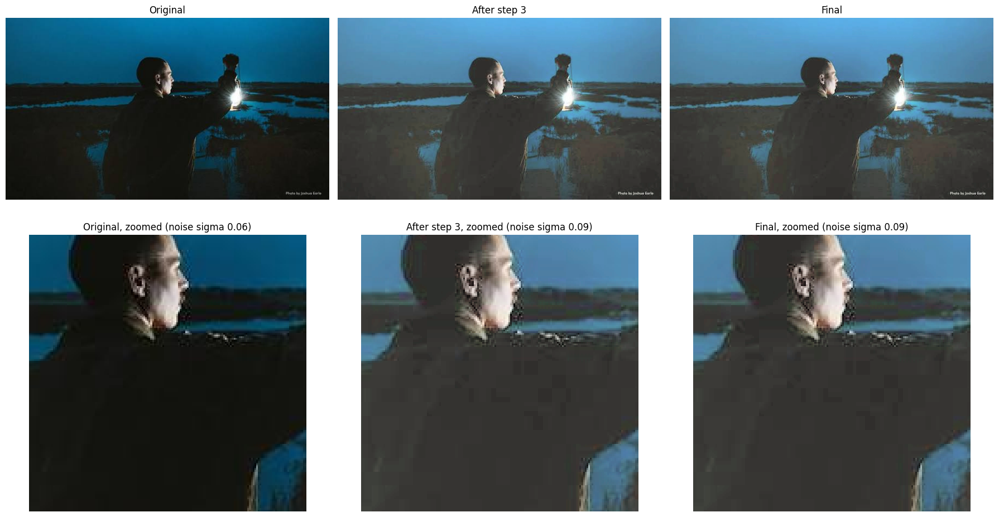

In [35]:
#run on my photo
# What: runs the full pipeline on your photo and shows the original, the step 3 result and the final result, with a zoomed centre crop under each.
# Why: noise is hard to see at full size, so the zoomed crops (shown with nearest-neighbour pixels) make the grain and its removal visible.
pipe = run_pipeline(data["bgr"])
print("Applied:", pipe["applied"], "|", pipe["reason"])
print("Steps:", pipe["steps"], "| Params:", pipe["params"])

a0, a1, a2 = analyze_all(data["bgr"]), analyze_all(res["image"]), pipe["after"]     # res = step 3 result
print(pd.DataFrame([{"check": n,
                     "original": f"{a0['by_name'][n]['value']} ({a0['by_name'][n]['label']})",
                     "after step 3": f"{a1['by_name'][n]['value']} ({a1['by_name'][n]['label']})",
                     "final": f"{a2['by_name'][n]['value']} ({a2['by_name'][n]['label']})"} for n in WEIGHTS_ALL]).to_string(index=False))
print("Overall:", a0["overall"], "->", a1["overall"], "->", a2["overall"])

imgs = [("Original", data["bgr"]), ("After step 3", res["image"]), ("Final", pipe["image"])]
h, w = data["bgr"].shape[:2]; cs = min(160, h, w); y0, x0 = (h - cs) // 2, (w - cs) // 2     # centre crop
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for j, (name, im) in enumerate(imgs):
    axes[0, j].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); axes[0, j].set_title(name); axes[0, j].axis("off")
    axes[1, j].imshow(cv2.cvtColor(im[y0:y0+cs, x0:x0+cs], cv2.COLOR_BGR2RGB), interpolation="nearest")
    axes[1, j].set_title(f"{name}, zoomed (noise sigma {analyze_all(im)['by_name']['noise']['value']})"); axes[1, j].axis("off")
plt.tight_layout(); plt.show()

             case  applied               reason PSNR before PSNR after PSNR plain blur 5x5   noise sigma
    Gaussian s=10    [nlm]  accepted (gain 1.1)        28.1       36.8                34.4  6.74 -> 0.57
    Gaussian s=20    [nlm]  accepted (gain 7.5)        22.1       32.9                31.5 13.38 -> 1.31
   Salt-pepper 3% [median] accepted (gain -2.3)        20.3       37.2                30.0  2.41 -> 0.09
Clean (reference)       []        no fix needed           -          -                   -  0.09 -> 0.09

Second pass on final image: [] | no fix needed


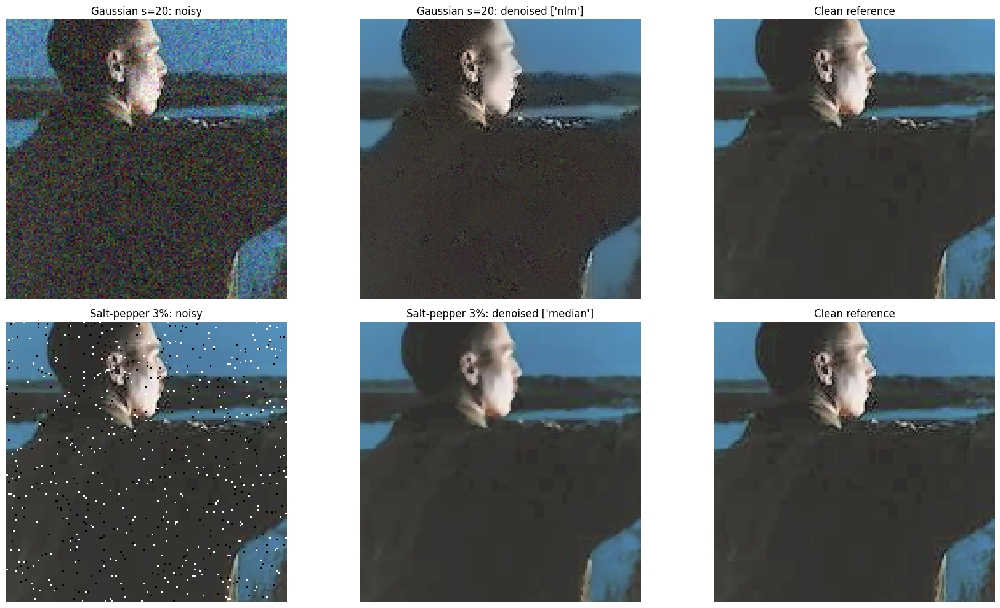

In [36]:
#test on damaged and clean ones
# What: takes your final image as a clean reference, adds Gaussian noise (two strengths) and salt-and-pepper noise, denoises each, and measures PSNR against the reference.
# Why: we know the right answer here, so PSNR (higher is better) is an objective score, and the clean copy and the second pass test the "leave good images alone" rule.
def add_salt_pepper(bgr, amount=0.03, seed=1):
    out = bgr.copy()
    r = np.random.default_rng(seed).random(bgr.shape[:2])
    out[r < amount / 2] = 0                                # pepper: whole pixel goes black
    out[r > 1 - amount / 2] = 255                          # salt: whole pixel goes white
    return out

ref = pipe["image"]
cases = {"Gaussian s=10": add_noise(ref, 10), "Gaussian s=20": add_noise(ref, 20),      # add_noise is defined in step 4
         "Salt-pepper 3%": add_salt_pepper(ref, 0.03), "Clean (reference)": ref}

dn = {}
rows = []
for name, img in cases.items():
    r = run_denoise(img); dn[name] = r
    rows.append({"case": name, "applied": r["applied"], "reason": r["reason"],
                 "PSNR before": round(cv2.PSNR(ref, img), 1) if name != "Clean (reference)" else "-",
                 "PSNR after": round(cv2.PSNR(ref, r["image"]), 1) if name != "Clean (reference)" else "-",
                 "PSNR plain blur 5x5": round(cv2.PSNR(ref, cv2.GaussianBlur(img, (5, 5), 0)), 1) if name != "Clean (reference)" else "-",
                 "noise sigma": f"{r['before']['by_name']['noise']['value']} -> {r['after']['by_name']['noise']['value']}"})
print(pd.DataFrame(rows).to_string(index=False))

second = run_denoise(pipe["image"])                        # a second pass on the final image
print("\nSecond pass on final image:", second["applied"], "|", second["reason"])

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for j, name in enumerate(["Gaussian s=20", "Salt-pepper 3%"]):
    crop = lambda im: cv2.cvtColor(im[y0:y0+cs, x0:x0+cs], cv2.COLOR_BGR2RGB)
    axes[j, 0].imshow(crop(cases[name]), interpolation="nearest"); axes[j, 0].set_title(f"{name}: noisy")
    axes[j, 1].imshow(crop(dn[name]["image"]), interpolation="nearest"); axes[j, 1].set_title(f"{name}: denoised {dn[name]['applied']}")
    axes[j, 2].imshow(crop(ref), interpolation="nearest"); axes[j, 2].set_title("Clean reference")
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); plt.show()

Tilt detection and fix. This step measures how far the picture is rotated from level and rotates it back. It acts only when the tilt is clearly more than 1°, and only when the photo has straight lines to measure.

In [38]:
# What: sets the tilt search window, the voting rules, the confidence needed, the tilt limit and the new overall weights that include tilt.
# Why: a photo only gets rotated if enough strong edges agree on one angle, so scenes without straight lines are left alone.
TILT = {
    "window": 15.0,          # only tilts within +-15 degrees are searched, bigger angles are treated as intentional
    "bin": 0.5,              # histogram bin width in degrees
    "peak_halfwidth": 1.0,   # edges within 1 degree of the peak count as agreeing with it
    "grad_pct": 90,          # only the strongest 10 percent of gradients vote
    "min_mag": 20.0,         # and they must be strong in absolute terms, so flat dark areas cast no votes
    "min_pixels": 500,       # fewer strong pixels than this means no reliable estimate
    "min_conf": 0.10,        # at least 10 percent of strong edges must agree (random content gives about 2 percent)
}
LIMITS["tilt"] = {"limit": 0.5, "margin": 0.5}      # above 0.5 degrees is tilted, clearly tilted (fixable) above 1.0 degree
WEIGHTS_FULL = {"brightness": 0.22, "contrast": 0.22, "clipping": 0.08, "blur": 0.22, "noise": 0.13, "tilt": 0.13}

In [39]:
# measure the tilt
# What: finds the dominant edge direction near horizontal/vertical by letting every strong Sobel gradient vote, weighted by its strength.
# Why: folding angles into +-45 degrees makes horizontal and vertical edges vote for the same tilt, and the confidence says whether the scene has real straight lines.
def tilt_stats(gray):
    g = gray.astype(np.float32)
    sm = cv2.GaussianBlur(g, (0, 0), 1.5)                               # smooth first so noise does not create fake gradient directions
    gx = cv2.Sobel(sm, cv2.CV_32F, 1, 0, ksize=3)                       # horizontal change
    gy = cv2.Sobel(sm, cv2.CV_32F, 0, 1, ksize=3)                       # vertical change
    mag = np.hypot(gx, gy)                                              # edge strength
    strong = (mag >= np.percentile(mag, TILT["grad_pct"])) & (mag > TILT["min_mag"])
    empty = {"tilt": 0.0, "conf": 0.0, "peak": 0.0, "d": np.array([]), "w": np.array([])}
    if strong.sum() < TILT["min_pixels"]:
        return empty
    phi = np.degrees(np.arctan2(gy[strong], gx[strong]))                # gradient direction of each strong pixel
    d = (phi + 45) % 90 - 45                                            # fold into [-45, 45): 0 means perfectly level or plumb
    w = mag[strong]
    win = np.abs(d) <= TILT["window"]
    if win.sum() == 0:
        return empty
    edges = np.arange(-TILT["window"], TILT["window"] + TILT["bin"], TILT["bin"])
    hist, _ = np.histogram(d[win], bins=edges, weights=w[win])          # weighted vote count per angle
    smooth = np.convolve(hist, np.ones(3) / 3, mode="same")             # smooth over neighbouring bins
    centers = (edges[:-1] + edges[1:]) / 2
    peak = float(centers[np.argmax(smooth)])
    near = np.abs(d - peak) <= TILT["peak_halfwidth"]
    if w[near].sum() == 0:
        return empty
    tilt = float(np.average(d[near], weights=w[near]))                  # refined angle: weighted mean of the agreeing edges
    conf = float(w[near].sum() / w.sum())                               # share of all strong-edge weight that agrees on this angle
    return {"tilt": tilt, "conf": conf, "peak": peak, "d": d, "w": w}

In [40]:
#The tilt check and the full analysis
# What: turns the tilt measurement into a check row in the same format as the other checks, and adds it to the overall score.
# Why: "no clear lines" counts as ok with a perfect score, so scenes with nothing to measure are never penalised or rotated.
def check_tilt(gray):
    ts = tilt_stats(gray)
    T = LIMITS["tilt"]
    if ts["conf"] < TILT["min_conf"]:
        return {"name": "tilt", "value": float("nan"), "status": "ok", "score": 100.0, "label": "no clear lines"}, ts
    status, score = judge(abs(ts["tilt"]) - T["limit"], T["margin"], 10)     # score falls to 0 at 10 degrees past the limit
    label = {"ok": "level", "borderline": "slightly tilted", "fail": "tilted"}[status]
    return {"name": "tilt", "value": round(ts["tilt"], 2), "status": status, "score": score, "label": label}, ts

def analyze_full(bgr):
    a = analyze_all(bgr)                                                     # the five checks from steps 2 and 4
    row, ts = check_tilt(cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY))
    by_name = {**a["by_name"], "tilt": row}
    overall = sum(WEIGHTS_FULL[n] * by_name[n]["score"] for n in WEIGHTS_FULL) / sum(WEIGHTS_FULL.values())
    return {**a, "checks": a["checks"] + [row], "by_name": by_name, "overall": round(overall, 1), "tilt": ts}

In [41]:
# The rotation fix with crop
# What: rotates the image to cancel the tilt, then crops the largest centred rectangle of the same shape that contains no black corners.
# Why: cropping removes the corners without resampling again, and keeping the aspect ratio means later steps see the same shape.
def fix_tilt(bgr, tilt_deg):
    h, w = bgr.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), tilt_deg, 1.0)               # positive angle = counter-clockwise, which cancels a clockwise tilt
    rot = cv2.warpAffine(bgr, M, (w, h), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0))
    th = np.radians(abs(tilt_deg))
    s = np.cos(th) + np.sin(th) * max(w / h, h / w)                          # how much smaller the largest clean rectangle is
    wc, hc = int(w / s) - 6, int(h / s) - 6                                  # 3 px safety margin per side for interpolation edges
    x0, y0 = (w - wc) // 2, (h - hc) // 2
    out = rot[y0:y0 + hc, x0:x0 + wc].copy()
    return out, {"tilt_deg": round(float(tilt_deg), 2), "crop_size": (wc, hc), "kept_pct": round(100 * wc * hc / (w * h), 1)}

In [42]:
# Tilt fix with guard, and the extended pipeline
# What: rotates only when tilt clearly fails, verifies the new tilt is smaller and no other check got worse, then chains tilt, exposure and denoise.
# Why: the guard rejects a rotation it cannot verify, and the chain is rejected as a whole if the final overall score is lower than the start.
def run_tilt(bgr):
    before = analyze_full(bgr)
    tb = before["by_name"]["tilt"]
    if tb["status"] != "fail":                                               # ok, borderline and "no clear lines" are all left alone
        reason = "no clear lines, left alone" if tb["label"] == "no clear lines" else "no fix needed"
        return {"image": bgr, "before": before, "after": before, "applied": [], "params": {}, "accepted": False, "reason": reason}
    angle = before["tilt"]["tilt"]
    cand, p = fix_tilt(bgr, angle)
    after = analyze_full(cand)
    ta = after["by_name"]["tilt"]
    verified = ta["label"] != "no clear lines" and ta["status"] != "fail" and abs(after["tilt"]["tilt"]) < abs(angle)
    regressed = [n for n in WEIGHTS_FULL if n != "tilt" and before["by_name"][n]["status"] != "fail" and after["by_name"][n]["status"] == "fail"]
    if verified and not regressed:
        return {"image": cand, "before": before, "after": after, "applied": ["rotate"], "params": p, "accepted": True,
                "reason": f"accepted ({angle:+.2f} deg, kept {p['kept_pct']}% of the area)"}
    why = "could not verify the result" if not verified else f"regressed: {regressed}"
    return {"image": bgr, "before": before, "after": before, "applied": [], "params": {}, "accepted": False, "reason": f"rejected ({why})"}

def run_pipeline_v2(bgr):
    start = analyze_full(bgr)
    t = run_tilt(bgr)                                      # geometry first, so later steps measure the final pixel layout
    e = run_exposure_contrast(t["image"])                  # step 3
    d = run_denoise(e["image"])                            # step 5
    final = analyze_full(d["image"])
    applied = t["applied"] + e["applied"] + d["applied"]
    steps = {"tilt": t["reason"], "exposure": e["reason"], "denoise": d["reason"]}
    gain = final["overall"] - start["overall"]
    if applied and gain < 0:                               # every step passed its own guard, but the chain as a whole must not be worse
        return {"image": bgr, "before": start, "after": start, "applied": [], "params": {}, "accepted": False,
                "reason": f"rejected (overall gain {gain:.1f})", "steps": steps}
    return {"image": d["image"], "before": start, "after": final, "applied": applied, "params": {**t["params"], **e["params"], **d["params"]},
            "accepted": bool(applied), "reason": "no fix needed" if not applied else f"accepted (gain {gain:.1f})", "steps": steps}

Tilt: nan deg (no clear lines) | confidence 0.05 (needs >= 0.1) | strong edges used: 19895
Applied: [] | no clear lines, left alone | {}


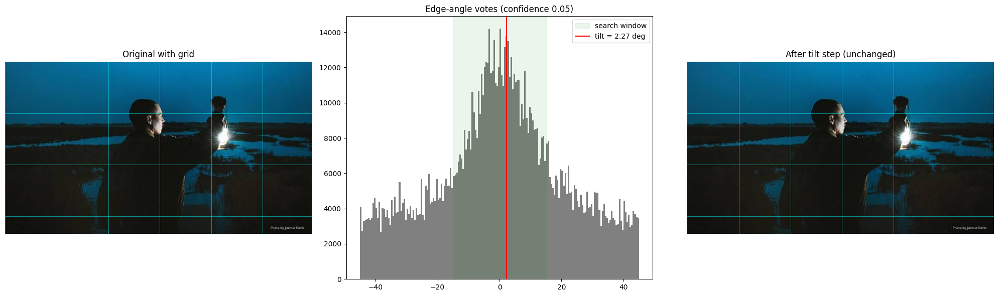

In [43]:
# Run it on your photo
# What: measures your photo's tilt and confidence, runs the tilt fix, and shows the original, the edge-angle histogram and the result with a grid.
# Why: the histogram shows the evidence behind the verdict (a sharp peak means real straight lines), and the grid lets you check by eye that lines are now level.
ref_a = analyze_full(data["bgr"])
ts, row = ref_a["tilt"], ref_a["by_name"]["tilt"]
print(f"Tilt: {row['value']} deg ({row['label']}) | confidence {ts['conf']:.2f} (needs >= {TILT['min_conf']}) | strong edges used: {len(ts['d'])}")

r = run_tilt(data["bgr"])
print("Applied:", r["applied"], "|", r["reason"], "|", r["params"])

def with_grid(ax, im, title):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.set_title(title); ax.axis("off")
    for y in range(0, im.shape[0], 100): ax.axhline(y, color="cyan", lw=0.6, alpha=0.6)    # horizontal guide lines
    for x in range(0, im.shape[1], 100): ax.axvline(x, color="cyan", lw=0.6, alpha=0.6)    # vertical guide lines

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
with_grid(axes[0], data["bgr"], "Original with grid")
if len(ts["d"]):
    axes[1].hist(ts["d"], bins=np.arange(-45, 45.5, 0.5), weights=ts["w"], color="gray")   # all strong edges, folded to +-45 degrees
    axes[1].axvspan(-TILT["window"], TILT["window"], color="green", alpha=0.08, label="search window")
    axes[1].axvline(ts["tilt"], color="red", label=f"tilt = {ts['tilt']:.2f} deg")
axes[1].set_title(f"Edge-angle votes (confidence {ts['conf']:.2f})"); axes[1].legend()
with_grid(axes[2], r["image"], "After tilt step" + ("" if r["accepted"] else " (unchanged)"))
plt.tight_layout(); plt.show()

Level reference residual tilt: 2.27 deg
 rotated cw  expected  measured  error  conf                     action residual
       -7.0     -4.73     -4.76  -0.03  0.04 no clear lines, left alone     None
       -3.0     -0.73     -0.28   0.44  0.05 no clear lines, left alone     None
        0.7      2.97      0.22  -2.75  0.05 no clear lines, left alone     None
        5.0      7.27      0.74  -6.53  0.04 no clear lines, left alone     None
       10.0     12.27      8.26  -4.02  0.04 no clear lines, left alone     None

No-lines image: confidence 0.00 | no clear lines, left alone
Level reference, second pass: [] | no clear lines, left alone

Combined case: ['gamma', 'nlm'] | accepted (gain 30.0) | {'tilt': 'no clear lines, left alone', 'exposure': 'accepted (gain 57.7)', 'denoise': 'accepted (gain 5.8)'}
Overall: 60.0 -> 90.0


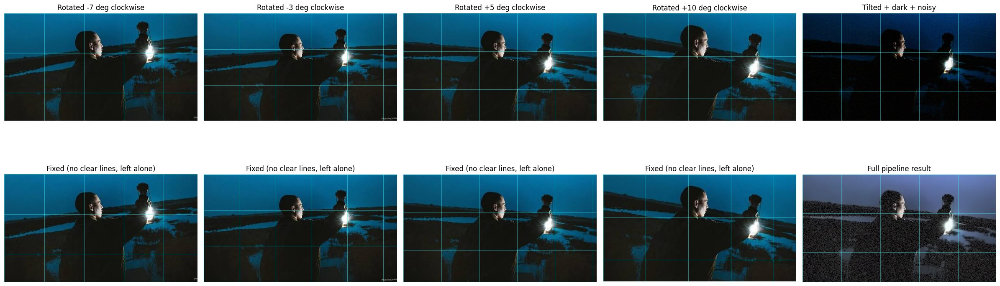

In [44]:
# Tests with known rotations
# What: makes a level reference from your photo, rotates it by known angles, and checks that the measured tilt matches and that the fix levels it.
# Why: we know the right answer, so the error column is an objective score, and the no-lines image and the level photo test the "leave it alone" rule.
a_ref = analyze_full(data["bgr"])
level = fix_tilt(data["bgr"], a_ref["tilt"]["tilt"])[0] if a_ref["by_name"]["tilt"]["status"] == "fail" else data["bgr"]   # remove any real tilt first
base_t = analyze_full(level)["tilt"]["tilt"]                                      # the reference's own small residual tilt

def rotate_cw(bgr, cw):
    return fix_tilt(bgr, -cw)[0]                                                  # rotating by -cw degrees turns the content cw degrees clockwise

rows, cases = [], {}
for cw in [-7, -3, 0.7, 5, 10]:
    img = rotate_cw(level, cw)
    a = analyze_full(img); rr = run_tilt(img)
    resid = analyze_full(rr["image"])["tilt"]["tilt"] if rr["accepted"] else None
    cases[cw] = {"img": img, "a": a, "run": rr}
    rows.append({"rotated cw": cw, "expected": round(base_t + cw, 2), "measured": round(a["tilt"]["tilt"], 2),
                 "error": round(a["tilt"]["tilt"] - (base_t + cw), 2), "conf": round(a["tilt"]["conf"], 2),
                 "action": "fixed" if rr["accepted"] else rr["reason"], "residual": None if resid is None else round(resid, 2)})
print("Level reference residual tilt:", round(base_t, 2), "deg")
print(pd.DataFrame(rows).to_string(index=False))

# a scene with no straight lines: heavily blurred random noise
h, w = data["bgr"].shape[:2]
blobs = cv2.GaussianBlur(np.random.default_rng(0).normal(128, 40, (h, w)).astype(np.float32), (0, 0), 6)
no_lines = cv2.cvtColor(np.clip(blobs, 0, 255).astype(np.uint8), cv2.COLOR_GRAY2BGR)
nl = run_tilt(no_lines); nl_conf = analyze_full(no_lines)["tilt"]["conf"]
print(f"\nNo-lines image: confidence {nl_conf:.2f} | {nl['reason']}")
lv = run_tilt(level)
print("Level reference, second pass:", lv["applied"], "|", lv["reason"])

# a combined case: tilted, dark and noisy at once
lut = (255 * (np.arange(256) / 255.0) ** 2.0).astype(np.uint8)
combo = add_noise(cv2.LUT(rotate_cw(level, 6), lut), 6)                          # add_noise is from step 4
p2 = run_pipeline_v2(combo)
print("\nCombined case:", p2["applied"], "|", p2["reason"], "|", p2["steps"])
print("Overall:", p2["before"]["overall"], "->", p2["after"]["overall"])

fig, axes = plt.subplots(2, 5, figsize=(24, 9))
for j, cw in enumerate([-7, -3, 5, 10]):
    with_grid(axes[0, j], cases[cw]["img"], f"Rotated {cw:+} deg clockwise")
    with_grid(axes[1, j], cases[cw]["run"]["image"], f"Fixed ({cases[cw]['run']['reason'][:28]})")
with_grid(axes[0, 4], combo, "Tilted + dark + noisy"); with_grid(axes[1, 4], p2["image"], "Full pipeline result")
plt.tight_layout(); plt.show()

Perspective and lens-distortion fixes
Perspective: find the main four-sided object in the frame (a page, whiteboard or sign). If its corners are clearly skewed, flatten it into a top-down rectangle.
Lens distortion: a single photo can’t reveal its own lens distortion, so this fix needs the calibration file from your earlier calibration topic. It undistorts only when the file matches the photo and the correction would be visible.

In [46]:
# What: sets the rules for accepting a quad as the main subject, the skew and distortion limits, and the overall weights with the two new checks.
# Why: a quad must be large, convex and sit on real edges, and a fix needs a clear error, so ordinary photos are left alone.
PERSP = {
    "enabled": True,          # set to False to skip perspective correction entirely
    "min_area_pct": 30,       # the quad must cover at least 30 percent of the frame to count as the main subject
    "max_area_pct": 98,       # ...and must not be the frame border itself
    "eps": 0.02,              # polygon simplification: 2 percent of the contour perimeter
    "min_support": 0.6,       # at least 60 percent of the quad outline must lie on real Canny edges
    "inset_px": 4,            # trim this many pixels inward so the edge band is not warped into the result
    "canny": (50, 150),
}
LIMITS["perspective"] = {"limit": 3.0, "margin": 2.0}     # max corner-angle error vs 90 degrees: above 3 skewed, fixable above 5
LIMITS["distortion"]  = {"limit": 0.5, "margin": 0.5}     # corner displacement in percent of the diagonal: fixable above 1.0
WEIGHTS_V3 = {"brightness": 0.20, "contrast": 0.20, "clipping": 0.07, "blur": 0.20, "noise": 0.11,
              "tilt": 0.10, "perspective": 0.07, "distortion": 0.05}
CALIB = None                                              # holds the camera calibration once one is loaded (cell 3 and cell 7)

In [47]:
#perspective check and fix
# What: finds the largest convex four-corner outline backed by real edges, measures how far its corners are from right angles, and warps it flat.
# Why: edge support and the angle test stop random shapes from being "fixed", and the corner-angle metric ignores plain rotation, which the tilt step handles.
def order_corners(pts):
    pts = np.asarray(pts, np.float32).reshape(4, 2)
    s, d = pts.sum(axis=1), pts[:, 1] - pts[:, 0]                  # x+y and y-x single out the corners
    return np.array([pts[np.argmin(s)], pts[np.argmin(d)], pts[np.argmax(s)], pts[np.argmax(d)]], np.float32)   # tl, tr, br, bl

def corner_angles(q):
    out = []
    for i in range(4):
        a, b = q[i - 1] - q[i], q[(i + 1) % 4] - q[i]              # the two edges meeting at corner i
        cosv = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-9)
        out.append(np.degrees(np.arccos(np.clip(cosv, -1, 1))))
    return np.array(out)

def edge_support(edges, q, n=60, radius=4):
    near = cv2.dilate(edges, np.ones((2 * radius + 1, 2 * radius + 1), np.uint8)) > 0      # pixels within 4 px of an edge
    hits = total = 0
    for i in range(4):
        for t in np.linspace(0, 1, n):
            x, y = (1 - t) * q[i] + t * q[(i + 1) % 4]             # sample points along each side
            xi, yi = int(round(x)), int(round(y))
            if 0 <= yi < near.shape[0] and 0 <= xi < near.shape[1]:
                hits += int(near[yi, xi])
            total += 1                                             # points outside the frame count as unsupported
    return hits / total

def find_quad(gray):
    h, w = gray.shape
    edges = cv2.Canny(cv2.GaussianBlur(gray, (5, 5), 0), *PERSP["canny"])
    closed = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_RECT, (7, 7)))   # join broken edge pieces
    contours, _ = cv2.findContours(closed, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
    best = None
    for c in contours:
        area = cv2.contourArea(c); pct = 100 * area / (h * w)
        if not (PERSP["min_area_pct"] <= pct <= PERSP["max_area_pct"]):
            continue                                               # too small to be the subject, or just the frame border
        approx = cv2.approxPolyDP(c, PERSP["eps"] * cv2.arcLength(c, True), True)
        if len(approx) != 4 or not cv2.isContourConvex(approx):
            continue
        q = order_corners(approx)
        ang = corner_angles(q)
        if ang.min() < 45 or ang.max() > 135:
            continue                                               # degenerate shape
        support = edge_support(edges, q)
        if support < PERSP["min_support"]:
            continue                                               # outline is not on real edges
        if best is None or area > best["area"]:
            best = {"quad": q, "area": area, "area_pct": pct, "support": support, "skew": float(np.abs(ang - 90).max())}
    return best

def check_perspective(gray):
    info = find_quad(gray) if PERSP["enabled"] else None
    if info is None:
        return {"name": "perspective", "value": float("nan"), "status": "ok", "score": 100.0, "label": "no dominant quad"}, None
    L = LIMITS["perspective"]
    status, score = judge(info["skew"] - L["limit"], L["margin"], 20)
    label = {"ok": "straight-on", "borderline": "slightly skewed", "fail": "skewed"}[status]
    return {"name": "perspective", "value": round(info["skew"], 1), "status": status, "score": score, "label": label}, info

def fix_perspective(bgr, quad):
    c = quad.mean(axis=0)
    q = quad + (c - quad) / (np.linalg.norm(c - quad, axis=1, keepdims=True) + 1e-9) * PERSP["inset_px"]   # move each corner slightly inward
    tl, tr, br, bl = q
    W = int(max(np.linalg.norm(br - bl), np.linalg.norm(tr - tl)))      # width: the longer of top and bottom edges
    H = int(max(np.linalg.norm(tr - br), np.linalg.norm(tl - bl)))      # height: the longer of left and right edges
    dst = np.array([[0, 0], [W - 1, 0], [W - 1, H - 1], [0, H - 1]], np.float32)
    M = cv2.getPerspectiveTransform(q.astype(np.float32), dst)
    out = cv2.warpPerspective(bgr, M, (W, H), flags=cv2.INTER_CUBIC)
    return out, {"quad": q.round(1).tolist(), "size": (W, H)}

In [48]:
# Lens distortion with a calibration file
# What: loads a calibration, rescales its camera matrix to the working size, estimates how big the correction would be, and undistorts then crops the clean region.
# Why: a mismatched or tiny correction only adds blur, so the check requires a matching image shape and a visible distortion before anything runs.
def load_calibration(path):
    d = np.load(path)
    size = tuple(int(v) for v in d["size"]) if "size" in d.files else None       # image size the calibration was made at
    return {"K": d["K"].astype(np.float64), "dist": d["dist"].astype(np.float64).ravel(), "size": size}

def scaled_K(calib, wh):
    w, h = wh; cw, ch = calib["size"]
    K = calib["K"].copy()
    K[0, :] *= w / cw; K[1, :] *= h / ch                      # focal length and principal point scale with the image size
    return K

def distortion_pct(K, dist, wh):
    w, h = wh
    pts = np.array([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1], [w / 2, 0], [w / 2, h - 1], [0, h / 2], [w - 1, h / 2]],
                   np.float32).reshape(-1, 1, 2)              # corners and edge midpoints, where distortion is largest
    und = cv2.undistortPoints(pts, K, dist, P=K).reshape(-1, 2)
    return float(100 * np.linalg.norm(und - pts.reshape(-1, 2), axis=1).max() / np.hypot(w, h))

def check_distortion(wh, done=False):
    ok = lambda label, v=float("nan"): ({"name": "distortion", "value": v, "status": "ok", "score": 100.0, "label": label}, None)
    if done:
        return ok("corrected", 0.0)
    if CALIB is None or CALIB.get("size") is None:
        return ok("no calibration")
    w, h = wh; cw, ch = CALIB["size"]
    if abs((w / h) / (cw / ch) - 1) > 0.02:
        return ok("calibration size mismatch")                # a different aspect ratio means a different crop or camera
    pct = distortion_pct(scaled_K(CALIB, wh), CALIB["dist"], wh)
    L = LIMITS["distortion"]
    status, score = judge(pct - L["limit"], L["margin"], 10)
    label = {"ok": "negligible", "borderline": "slight", "fail": "distorted"}[status]
    return {"name": "distortion", "value": round(pct, 2), "status": status, "score": score, "label": label}, {"pct": pct}

def fix_distortion(bgr, K, dist):
    h, w = bgr.shape[:2]
    newK, roi = cv2.getOptimalNewCameraMatrix(K, dist, (w, h), 1.0, (w, h))      # alpha=1 keeps every source pixel, roi marks the clean area
    und = cv2.undistort(bgr, K, dist, None, newK)
    x, y, rw, rh = roi; m = 3                                                      # 3 px safety margin against blended edge pixels
    if rw < 0.5 * w or rh < 0.5 * h:                                               # roi unusable, so fall back to the zoomed alpha=0 version
        newK0, _ = cv2.getOptimalNewCameraMatrix(K, dist, (w, h), 0.0, (w, h))
        out = cv2.undistort(bgr, K, dist, None, newK0)
    else:
        out = und[y + m:y + rh - m, x + m:x + rw - m].copy()
    return out, {"kept_pct": round(100 * out.shape[0] * out.shape[1] / (w * h), 1)}

In [49]:
#Full analysis, guarded fixes and the new pipeline
# What: adds the perspective and distortion rows to the analysis, wraps each fix in a guard, and chains everything in the corrected order.
# Why: each fix is verified (sane output size, no other check newly failing), and the whole chain is rejected if the final overall score is lower than the start.
def analyze_full3(bgr, dist_done=False):
    a = analyze_full(bgr)                                                    # the six checks from steps 2, 4 and 6
    h, w = bgr.shape[:2]
    prow, pinfo = check_perspective(cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY))
    drow, dinfo = check_distortion((w, h), done=dist_done)
    by_name = {**a["by_name"], "perspective": prow, "distortion": drow}
    overall = sum(WEIGHTS_V3[n] * by_name[n]["score"] for n in WEIGHTS_V3) / sum(WEIGHTS_V3.values())
    return {**a, "checks": a["checks"] + [prow, drow], "by_name": by_name, "overall": round(overall, 1), "quad": pinfo, "dist": dinfo}

def _skip(bgr, before, reason):
    return {"image": bgr, "before": before, "after": before, "applied": [], "params": {}, "accepted": False, "reason": reason}

def run_distortion(bgr):
    before = analyze_full3(bgr)
    db = before["by_name"]["distortion"]
    if db["status"] != "fail":
        return _skip(bgr, before, "no fix needed" if db["label"] in ("negligible", "slight") else f"skipped ({db['label']})")
    h, w = bgr.shape[:2]
    cand, p = fix_distortion(bgr, scaled_K(CALIB, (w, h)), CALIB["dist"])
    after = analyze_full3(cand, dist_done=True)                              # the distortion row is "corrected" now, so it is not re-judged
    regressed = [n for n in WEIGHTS_V3 if n != "distortion" and before["by_name"][n]["status"] != "fail" and after["by_name"][n]["status"] == "fail"]
    if p["kept_pct"] >= 50 and not regressed:
        return {"image": cand, "before": before, "after": after, "applied": ["undistort"], "params": p, "accepted": True,
                "reason": f"accepted (corner shift {db['value']}% of diagonal, kept {p['kept_pct']}% of the area)"}
    return _skip(bgr, before, "rejected (" + ("kept too little of the image" if p["kept_pct"] < 50 else f"regressed: {regressed}") + ")")

def run_perspective(bgr):
    before = analyze_full3(bgr, dist_done=True)                              # distortion is handled by its own step
    pb = before["by_name"]["perspective"]
    if pb["status"] != "fail":
        return _skip(bgr, before, "no dominant quad, left alone" if pb["label"] == "no dominant quad" else "no fix needed")
    h, w = bgr.shape[:2]
    cand, p = fix_perspective(bgr, before["quad"]["quad"])
    after = analyze_full3(cand, dist_done=True)
    W, H = p["size"]
    sane = W * H >= 0.15 * w * h and 0.2 <= W / max(H, 1) <= 5               # the result must not be tiny or extreme
    regressed = [n for n in WEIGHTS_V3 if n not in ("perspective", "tilt", "blur") and before["by_name"][n]["status"] != "fail" and after["by_name"][n]["status"] == "fail"]
    if sane and not regressed:
        return {"image": cand, "before": before, "after": after, "applied": ["warp"], "params": p, "accepted": True,
                "reason": f"accepted (corner error {pb['value']} deg, output {W}x{H})"}
    return _skip(bgr, before, "rejected (" + ("implausible output size" if not sane else f"regressed: {regressed}") + ")")

def run_pipeline_v3(bgr):
    start = analyze_full3(bgr)
    x = run_distortion(bgr)                                # geometry first, in the order the lens and camera produced it
    y = run_perspective(x["image"])
    t = run_tilt(y["image"])                               # step 6
    e = run_exposure_contrast(t["image"])                  # step 3
    d = run_denoise(e["image"])                            # step 5
    final = analyze_full3(d["image"], dist_done=bool(x["applied"]))
    applied = x["applied"] + y["applied"] + t["applied"] + e["applied"] + d["applied"]
    steps = {"distortion": x["reason"], "perspective": y["reason"], "tilt": t["reason"], "exposure": e["reason"], "denoise": d["reason"]}
    gain = final["overall"] - start["overall"]
    if applied and gain < 0:
        return {"image": bgr, "before": start, "after": start, "applied": [], "params": {}, "accepted": False,
                "reason": f"rejected (overall gain {gain:.1f})", "steps": steps}
    return {"image": d["image"], "before": start, "after": final, "applied": applied,
            "params": {"distortion": x["params"], "perspective": y["params"], "tilt": t["params"], "exposure": e["params"], "denoise": d["params"]},
            "accepted": bool(applied), "reason": "no fix needed" if not applied else f"accepted (gain {gain:.1f})", "steps": steps}

perspective: nan (no dominant quad)
distortion: nan (no calibration)
Perspective fix: [] | no dominant quad, left alone


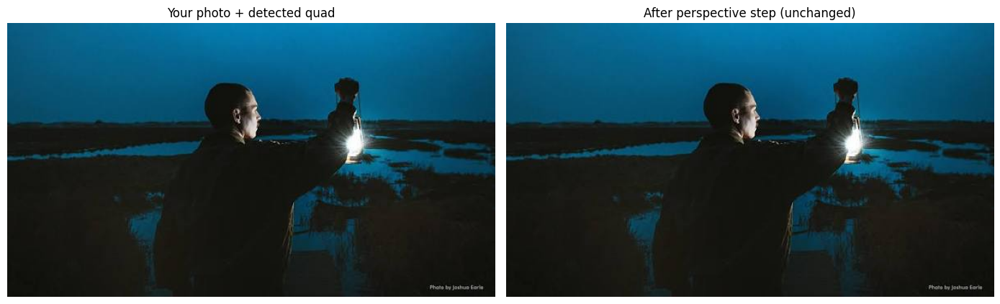

In [50]:
#run on my photo
# What: shows what the perspective check finds in your photo, with the detected outline drawn on it, and what the guarded fix does.
# Why: for most photos the answer should be "no dominant quad", and seeing the outline explains why when a quad is found.
a = analyze_full3(data["bgr"])
for n in ["perspective", "distortion"]:
    print(f"{n}: {a['by_name'][n]['value']} ({a['by_name'][n]['label']})")
if a["quad"]:
    q = a["quad"]; print(f"Quad covers {q['area_pct']:.0f}% of the frame, edge support {q['support']:.2f}, corner-angle error {q['skew']:.1f} deg")
r = run_perspective(data["bgr"])
print("Perspective fix:", r["applied"], "|", r["reason"])

vis = cv2.cvtColor(data["bgr"], cv2.COLOR_BGR2RGB).copy()
if a["quad"]:
    cv2.polylines(vis, [a["quad"]["quad"].astype(np.int32)], True, (255, 0, 0), 3)       # detected outline in red
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(vis); axes[0].set_title("Your photo + detected quad"); axes[0].axis("off")
axes[1].imshow(cv2.cvtColor(r["image"], cv2.COLOR_BGR2RGB)); axes[1].set_title("After perspective step" + ("" if r["accepted"] else " (unchanged)")); axes[1].axis("off")
plt.tight_layout(); plt.show()

        scene  quad found  area %  support  skew deg                                           action     output
  Skewed page        True    48.0      1.0      12.3 accepted (corner error 12.3 deg, output 586x459) (586, 459)
Straight page        True    42.0      1.0       0.0                                    no fix needed          -
 Rotated page        True    40.0      1.0       0.1                                    no fix needed          -
      No page       False     NaN      NaN       NaN                     no dominant quad, left alone          -

Skewed page: difference from the true page 4.4 grey levels | output aspect 1.28 vs true 1.30

Combined case: ['warp', 'gamma'] | accepted (gain 15.7)
Steps: {'distortion': 'skipped (no calibration)', 'perspective': 'accepted (corner error 12.3 deg, output 586x459)', 'tilt': 'no fix needed', 'exposure': 'accepted (gain 27.5)', 'denoise': 'no fix needed'}
Overall: 80.9 -> 96.6


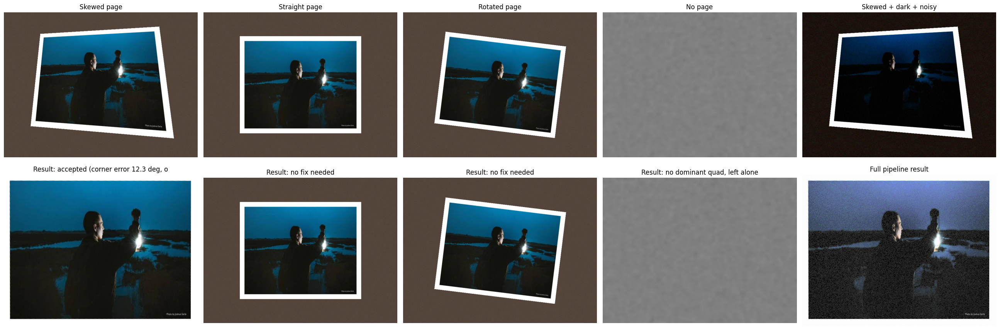

In [51]:
#test on synthetic images
# What: places your photo on a desk as a page seen at a steep angle, straight-on, rotated, and not at all, then runs the perspective step on each.
# Why: we know the original page, so the flattened result can be compared to it, and the straight, rotated and no-page scenes must be left alone.
def make_scene(page_bgr, dst, seed=0):
    page = cv2.copyMakeBorder(cv2.resize(page_bgr, (480, 360), interpolation=cv2.INTER_AREA), 20, 20, 20, 20, cv2.BORDER_CONSTANT, value=(255, 255, 255))   # 520x400 page with white margin
    canvas = np.clip(np.array([60, 70, 85], np.float32) + np.random.default_rng(seed).normal(0, 4, (600, 800, 3)), 0, 255).astype(np.uint8)   # dark textured desk
    M = cv2.getPerspectiveTransform(np.float32([[0, 0], [519, 0], [519, 399], [0, 399]]), np.float32(dst))
    scene = cv2.warpPerspective(page, M, (800, 600), dst=canvas, flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_TRANSPARENT)   # paste the warped page onto the desk
    return scene, page

def page_error(out, page):
    g1 = cv2.GaussianBlur(cv2.cvtColor(cv2.resize(out, (page.shape[1], page.shape[0])), cv2.COLOR_BGR2GRAY), (0, 0), 3).astype(np.float32)
    g2 = cv2.GaussianBlur(cv2.cvtColor(page, cv2.COLOR_BGR2GRAY), (0, 0), 3).astype(np.float32)
    return float(np.abs(g1 - g2).mean())                      # mean grey-level difference after light smoothing

th = np.radians(7); R = np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])
dsts = {
    "Skewed page":   [[150, 90], [640, 60], [700, 520], [110, 470]],
    "Straight page": [[150, 100], [650, 100], [650, 500], [150, 500]],
    "Rotated page":  (np.array([[-250, -190], [250, -190], [250, 190], [-250, 190]]) @ R.T + [400, 300]).tolist(),
}
scenes = {}
for name, dst in dsts.items():
    scenes[name], page = make_scene(data["bgr"], dst)
blobs = cv2.GaussianBlur(np.random.default_rng(0).normal(128, 40, (600, 800)).astype(np.float32), (0, 0), 6)
scenes["No page"] = cv2.cvtColor(np.clip(blobs, 0, 255).astype(np.uint8), cv2.COLOR_GRAY2BGR)

res_p, rows = {}, []
for name, img in scenes.items():
    a = analyze_full3(img); rr = run_perspective(img); q = a["quad"]; res_p[name] = (a, rr)
    rows.append({"scene": name, "quad found": q is not None, "area %": None if q is None else round(q["area_pct"]),
                 "support": None if q is None else round(q["support"], 2), "skew deg": None if q is None else round(q["skew"], 1),
                 "action": rr["reason"], "output": rr["params"].get("size", "-")})
print(pd.DataFrame(rows).to_string(index=False))

err = page_error(res_p["Skewed page"][1]["image"], page)
Wo, Ho = res_p["Skewed page"][1]["params"].get("size", (1, 1))
print(f"\nSkewed page: difference from the true page {err:.1f} grey levels | output aspect {Wo/Ho:.2f} vs true {520/400:.2f}")

# a combined case: skewed, dark and noisy at once, through the whole pipeline
lut = (255 * (np.arange(256) / 255.0) ** 2.0).astype(np.uint8)
combo = add_noise(cv2.LUT(scenes["Skewed page"], lut), 6)            # add_noise is from step 4
p3 = run_pipeline_v3(combo)
print("\nCombined case:", p3["applied"], "|", p3["reason"]); print("Steps:", p3["steps"])
print("Overall:", p3["before"]["overall"], "->", p3["after"]["overall"])

fig, axes = plt.subplots(2, 5, figsize=(26, 9))
for j, (name, img) in enumerate(scenes.items()):
    axes[0, j].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); axes[0, j].set_title(name); axes[0, j].axis("off")
    axes[1, j].imshow(cv2.cvtColor(res_p[name][1]["image"], cv2.COLOR_BGR2RGB)); axes[1, j].set_title("Result: " + res_p[name][1]["reason"][:34]); axes[1, j].axis("off")
axes[0, 4].imshow(cv2.cvtColor(combo, cv2.COLOR_BGR2RGB)); axes[0, 4].set_title("Skewed + dark + noisy"); axes[0, 4].axis("off")
axes[1, 4].imshow(cv2.cvtColor(p3["image"], cv2.COLOR_BGR2RGB)); axes[1, 4].set_title("Full pipeline result"); axes[1, 4].axis("off")
plt.tight_layout(); plt.show()

Strong distortion: 7.66 % | distorted | accepted (corner shift 7.66% of diagonal, kept 83.2% of the area)
PSNR vs original (centre): distorted 28.5 dB -> undistorted 40.2 dB
White-image minimum after fix: 255 | half-size fx: 268.2 (expected 268.2)
Slight distortion: 0.63 % | slight | no fix needed
No calibration: no calibration | skipped (no calibration)
Wrong-shaped calibration: calibration size mismatch


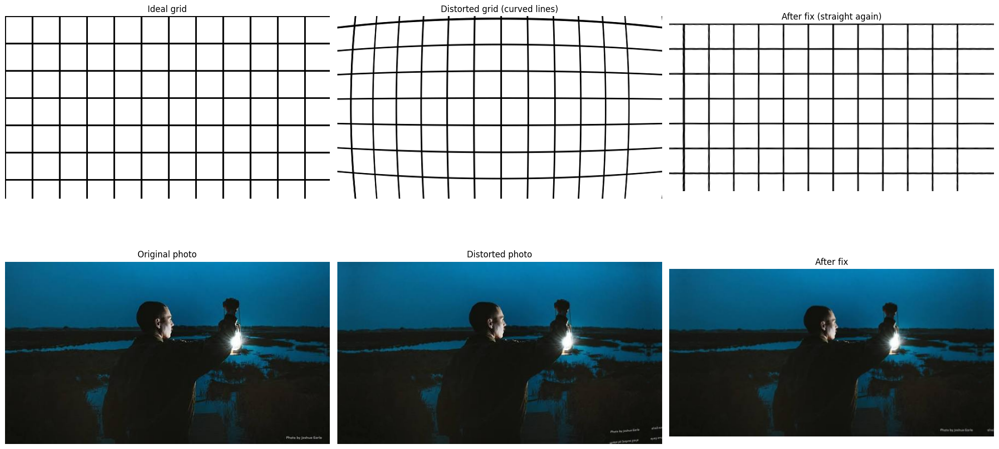

In [52]:
#lens distortion with synthetic tests
# What: distorts your photo with a known lens model, saves and reloads that calibration, and checks the fix, the "slight" case, the no-calibration case and a size mismatch.
# Why: with a known lens we can measure the result against the undistorted original, and a grid makes the straightening visible.
def apply_distortion(img, K, dist):
    hh, ww = img.shape[:2]
    u, v = np.meshgrid(np.arange(ww), np.arange(hh))
    pts = np.stack([u, v], -1).reshape(-1, 1, 2).astype(np.float32)
    src = cv2.undistortPoints(pts, K, dist, P=K).reshape(hh, ww, 2)           # where each distorted pixel came from in the ideal image
    return cv2.remap(img, src[..., 0], src[..., 1], cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)

ideal = data["bgr"]; h, w = ideal.shape[:2]
K_true = np.array([[0.9 * w, 0, w / 2], [0, 0.9 * w, h / 2], [0, 0, 1]], np.float64)
strong = np.array([-0.30, 0.10, 0, 0, 0]); slight = np.array([-0.03, 0, 0, 0, 0])      # [k1, k2, p1, p2, k3]

np.savez("calibration_demo.npz", K=K_true, dist=strong, size=(w, h))           # the same file format a real calibration should use
CALIB = load_calibration("calibration_demo.npz")
distorted = apply_distortion(ideal, K_true, strong)
a_s = analyze_full3(distorted); r_s = run_distortion(distorted)
print("Strong distortion:", a_s["by_name"]["distortion"]["value"], "% |", a_s["by_name"]["distortion"]["label"], "|", r_s["reason"])

und_k = cv2.undistort(distorted, K_true, strong)                              # same geometry as the original, so it can be compared directly
sl = (slice(int(.2 * h), int(.8 * h)), slice(int(.2 * w), int(.8 * w)))       # central 60 percent, where information survives
psnr_before, psnr_after = cv2.PSNR(distorted[sl], ideal[sl]), cv2.PSNR(und_k[sl], ideal[sl])
print(f"PSNR vs original (centre): distorted {psnr_before:.1f} dB -> undistorted {psnr_after:.1f} dB")

wd = apply_distortion(np.full(ideal.shape, 255, np.uint8), K_true, strong)    # an all-white image shows black borders immediately
white_min = fix_distortion(wd, K_true, strong)[0].min()
Ks = scaled_K({"K": K_true, "size": (w, h)}, (w // 2, h // 2))
print(f"White-image minimum after fix: {white_min} | half-size fx: {Ks[0, 0]:.1f} (expected {K_true[0, 0] / 2:.1f})")

CALIB = {"K": K_true, "dist": slight, "size": (w, h)}
a_sl = analyze_full3(apply_distortion(ideal, K_true, slight)); r_sl = run_distortion(apply_distortion(ideal, K_true, slight))
print("Slight distortion:", a_sl["by_name"]["distortion"]["value"], "% |", a_sl["by_name"]["distortion"]["label"], "|", r_sl["reason"])
CALIB = None
a_nc = analyze_full3(distorted); r_nc = run_distortion(distorted)
print("No calibration:", a_nc["by_name"]["distortion"]["label"], "|", r_nc["reason"])
CALIB = {"K": K_true, "dist": strong, "size": (640, 640)}
a_mm = analyze_full3(distorted)
print("Wrong-shaped calibration:", a_mm["by_name"]["distortion"]["label"])
CALIB = load_calibration("calibration_demo.npz")                              # re-load for the visual below

grid = np.full((h, w, 3), 255, np.uint8)
for x in range(0, w, 50): cv2.line(grid, (x, 0), (x, h - 1), (0, 0, 0), 2)
for y in range(0, h, 50): cv2.line(grid, (0, y), (w - 1, y), (0, 0, 0), 2)
gd = apply_distortion(grid, K_true, strong); gf = fix_distortion(gd, K_true, strong)[0]
pf = fix_distortion(distorted, K_true, strong)[0]
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
for ax, im, t in zip(axes.flat, [grid, gd, gf, ideal, distorted, pf],
                     ["Ideal grid", "Distorted grid (curved lines)", "After fix (straight again)", "Original photo", "Distorted photo", "After fix"]):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show()
CALIB = None                                                                  # reset: set your own calibration before using the pipeline on real photos

Strong distortion: 7.66 % | distorted | accepted (corner shift 7.66% of diagonal, kept 83.2% of the area)
PSNR vs original (centre): distorted 28.5 dB -> undistorted 40.2 dB
White-image minimum after fix: 255 | half-size fx: 268.2 (expected 268.2)
Slight distortion: 0.63 % | slight | no fix needed
No calibration: no calibration | skipped (no calibration)
Wrong-shaped calibration: calibration size mismatch


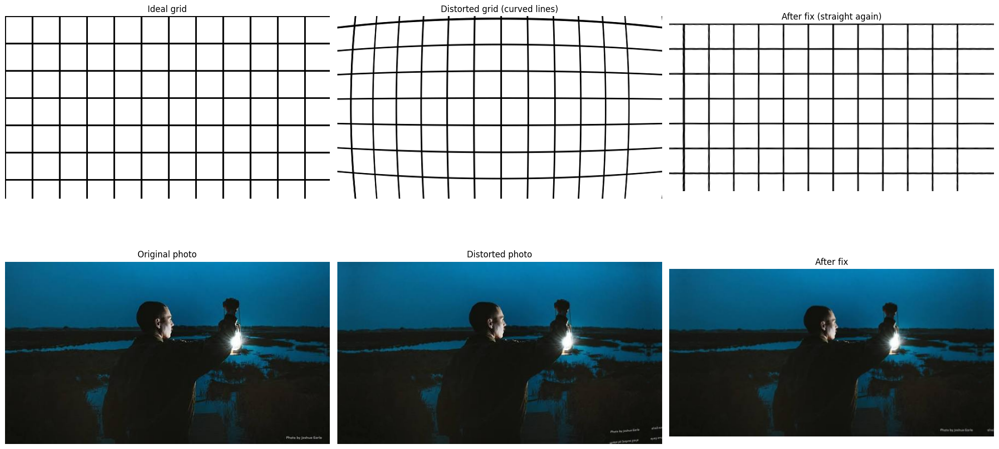

In [53]:
#lens distortion test on syntehtic data
# What: distorts your photo with a known lens model, saves and reloads that calibration, and checks the fix, the "slight" case, the no-calibration case and a size mismatch.
# Why: with a known lens we can measure the result against the undistorted original, and a grid makes the straightening visible.
def apply_distortion(img, K, dist):
    hh, ww = img.shape[:2]
    u, v = np.meshgrid(np.arange(ww), np.arange(hh))
    pts = np.stack([u, v], -1).reshape(-1, 1, 2).astype(np.float32)
    src = cv2.undistortPoints(pts, K, dist, P=K).reshape(hh, ww, 2)           # where each distorted pixel came from in the ideal image
    return cv2.remap(img, src[..., 0], src[..., 1], cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)

ideal = data["bgr"]; h, w = ideal.shape[:2]
K_true = np.array([[0.9 * w, 0, w / 2], [0, 0.9 * w, h / 2], [0, 0, 1]], np.float64)
strong = np.array([-0.30, 0.10, 0, 0, 0]); slight = np.array([-0.03, 0, 0, 0, 0])      # [k1, k2, p1, p2, k3]

np.savez("calibration_demo.npz", K=K_true, dist=strong, size=(w, h))           # the same file format a real calibration should use
CALIB = load_calibration("calibration_demo.npz")
distorted = apply_distortion(ideal, K_true, strong)
a_s = analyze_full3(distorted); r_s = run_distortion(distorted)
print("Strong distortion:", a_s["by_name"]["distortion"]["value"], "% |", a_s["by_name"]["distortion"]["label"], "|", r_s["reason"])

und_k = cv2.undistort(distorted, K_true, strong)                              # same geometry as the original, so it can be compared directly
sl = (slice(int(.2 * h), int(.8 * h)), slice(int(.2 * w), int(.8 * w)))       # central 60 percent, where information survives
psnr_before, psnr_after = cv2.PSNR(distorted[sl], ideal[sl]), cv2.PSNR(und_k[sl], ideal[sl])
print(f"PSNR vs original (centre): distorted {psnr_before:.1f} dB -> undistorted {psnr_after:.1f} dB")

wd = apply_distortion(np.full(ideal.shape, 255, np.uint8), K_true, strong)    # an all-white image shows black borders immediately
white_min = fix_distortion(wd, K_true, strong)[0].min()
Ks = scaled_K({"K": K_true, "size": (w, h)}, (w // 2, h // 2))
print(f"White-image minimum after fix: {white_min} | half-size fx: {Ks[0, 0]:.1f} (expected {K_true[0, 0] / 2:.1f})")

CALIB = {"K": K_true, "dist": slight, "size": (w, h)}
a_sl = analyze_full3(apply_distortion(ideal, K_true, slight)); r_sl = run_distortion(apply_distortion(ideal, K_true, slight))
print("Slight distortion:", a_sl["by_name"]["distortion"]["value"], "% |", a_sl["by_name"]["distortion"]["label"], "|", r_sl["reason"])
CALIB = None
a_nc = analyze_full3(distorted); r_nc = run_distortion(distorted)
print("No calibration:", a_nc["by_name"]["distortion"]["label"], "|", r_nc["reason"])
CALIB = {"K": K_true, "dist": strong, "size": (640, 640)}
a_mm = analyze_full3(distorted)
print("Wrong-shaped calibration:", a_mm["by_name"]["distortion"]["label"])
CALIB = load_calibration("calibration_demo.npz")                              # re-load for the visual below

grid = np.full((h, w, 3), 255, np.uint8)
for x in range(0, w, 50): cv2.line(grid, (x, 0), (x, h - 1), (0, 0, 0), 2)
for y in range(0, h, 50): cv2.line(grid, (0, y), (w - 1, y), (0, 0, 0), 2)
gd = apply_distortion(grid, K_true, strong); gf = fix_distortion(gd, K_true, strong)[0]
pf = fix_distortion(distorted, K_true, strong)[0]
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
for ax, im, t in zip(axes.flat, [grid, gd, gf, ideal, distorted, pf],
                     ["Ideal grid", "Distorted grid (curved lines)", "After fix (straight again)", "Original photo", "Distorted photo", "After fix"]):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show()
CALIB = None                                                                  # reset: set your own calibration before using the pipeline on real photos

Report, full-resolution output and one entry point. This step adds process_photo("photo.jpg"), which runs the whole pipeline and saves three files: the fixed photo, a report image and a report CSV

In [55]:
# What: loads the file and timing libraries, and sets the output quality, the full-resolution denoise window and the cap on denoise strength.
# Why: these only matter for the full-resolution replay, so they stay separate from the analysis settings.
import os, time, hashlib, shutil

FULL = {
    "jpg_quality": 95,        # quality of the saved fixed JPEG
    "nlm_search": 11,         # smaller search window than the 21 used at 800 px, so full-size denoising stays fast
    "h_cap": 15.0,            # highest non-local-means strength allowed at full resolution
}
FIX_FOR = {"brightness": ["gamma"], "contrast": ["stretch", "clahe"], "noise": ["median", "nlm"],
           "tilt": ["rotate"], "perspective": ["warp"], "distortion": ["undistort"], "blur": [], "clipping": []}   # which fixes handle which check

In [56]:
#replay helpers
# What: three small functions that apply a fix from recorded numbers (gamma value, stretch range, quad corners) without re-measuring anything.
# Why: the full-resolution photo must get the same fix the 800 px copy got, and re-measuring at a different size would give different numbers.
def apply_gamma(bgr, gamma):
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
    lut = np.clip(255 * (np.arange(256) / 255.0) ** gamma, 0, 255).astype(np.uint8)    # same lookup table as fix_brightness
    lab[..., 0] = cv2.LUT(lab[..., 0], lut)
    return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)

def apply_stretch(bgr, lo, hi):
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
    L = lab[..., 0].astype(np.float32)
    out = (L - lo) * (STRETCH_OUT[1] - STRETCH_OUT[0]) / (hi - lo) + STRETCH_OUT[0]    # same mapping as fix_stretch, with the recorded range
    lab[..., 0] = np.clip(out, 0, 255).astype(np.uint8)
    return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)

def warp_quad(bgr, q):
    tl, tr, br, bl = q                                          # corners are already inset, so no extra inset here
    W = int(max(np.linalg.norm(br - bl), np.linalg.norm(tr - tl)))
    H = int(max(np.linalg.norm(tr - br), np.linalg.norm(tl - bl)))
    dst = np.array([[0, 0], [W - 1, 0], [W - 1, H - 1], [0, H - 1]], np.float32)
    M = cv2.getPerspectiveTransform(np.asarray(q, np.float32), dst)
    return cv2.warpPerspective(bgr, M, (W, H), flags=cv2.INTER_CUBIC)

In [57]:
#Pipeline that records stages, and the full-resolution replay
# What: runs every stage on the 800 px copy while keeping each stage's result, then replays the accepted ones on the full-size photo in the same order.
# Why: if the whole chain was rejected, nothing is replayed, so the photo comes out unchanged and byte-identical.
def run_pipeline_v4(bgr):
    start = analyze_full3(bgr)
    x = run_distortion(bgr)
    y = run_perspective(x["image"])
    persp_in = (x["image"].shape[1], x["image"].shape[0])        # the quad's coordinates belong to this image size
    t = run_tilt(y["image"])
    e = run_exposure_contrast(t["image"])
    d = run_denoise(e["image"])
    final = analyze_full3(d["image"], dist_done=bool(x["applied"]))
    applied = x["applied"] + y["applied"] + t["applied"] + e["applied"] + d["applied"]
    steps = {"distortion": x["reason"], "perspective": y["reason"], "tilt": t["reason"], "exposure": e["reason"], "denoise": d["reason"]}
    gain = final["overall"] - start["overall"]
    base = {"stages": {"distortion": x, "perspective": y, "tilt": t, "exposure": e, "denoise": d},
            "perspective_in": persp_in, "denoise_in": e["image"], "steps": steps}
    if applied and gain < 0:                                     # every stage passed its guard, but the chain as a whole must not be worse
        return {**base, "image": bgr, "before": start, "after": start, "applied": [], "accepted": False, "reason": f"rejected (overall gain {gain:.1f})"}
    return {**base, "image": d["image"], "before": start, "after": final, "applied": applied, "accepted": bool(applied),
            "reason": "no fix needed" if not applied else f"accepted (gain {gain:.1f})"}

def replay_full(full, pipe):
    st, cur, log = pipe["stages"], full.copy(), []
    if st["distortion"]["applied"]:
        h, w = cur.shape[:2]
        cur, _ = fix_distortion(cur, scaled_K(CALIB, (w, h)), CALIB["dist"]); log.append("undistort")      # camera matrix rebuilt for the full size
    if st["perspective"]["applied"]:
        iw, ih = pipe["perspective_in"]
        q = np.array(st["perspective"]["params"]["quad"], np.float32) * np.array([cur.shape[1] / iw, cur.shape[0] / ih], np.float32)   # corners scaled to full size
        cur = warp_quad(cur, q); log.append("warp")
    if st["tilt"]["applied"]:
        cur = fix_tilt(cur, st["tilt"]["params"]["tilt_deg"])[0]; log.append("rotate")                    # an angle does not depend on resolution
    p = st["exposure"]["params"]
    for name in st["exposure"]["applied"]:
        if name == "gamma":                      cur = apply_gamma(cur, p["gamma"])
        elif name == "stretch" and "stretch_from" in p: cur = apply_stretch(cur, *p["stretch_from"])
        elif name == "clahe":                    cur = fix_clahe(cur, p["clahe_clip"])[0]
        log.append(name)
    p = st["denoise"]["params"]
    work_in = pipe["denoise_in"]
    if "median" in st["denoise"]["applied"]:
        cur = cv2.medianBlur(cur, p["median_k"]); work_in = cv2.medianBlur(work_in, p["median_k"]); log.append("median")
    if "nlm" in st["denoise"]["applied"]:
        s_work = noise_stats(cv2.cvtColor(work_in, cv2.COLOR_BGR2GRAY))["sigma"]
        s_full = noise_stats(cv2.cvtColor(cur, cv2.COLOR_BGR2GRAY))["sigma"]
        h = float(np.clip(p["nlm_h"] * s_full / max(s_work, 1.0), DENOISE["h_min"], FULL["h_cap"]))        # strength follows the noise measured at full size
        cur = cv2.fastNlMeansDenoisingColored(cur, None, h, h, DENOISE["template"], FULL["nlm_search"]); log.append(f"nlm(h={h:.1f})")
    return cur, log

In [58]:
#report table and figure
# What: builds one table row per check (before, after, status and the action taken) plus an overall-score row, and a before/after figure with histograms.
# Why: "flagged only" and "left alone (borderline)" are different outcomes from "fixed", and the report should say which one happened and why.
def fmt(c):
    return c["label"] if isinstance(c["value"], float) and np.isnan(c["value"]) else f"{c['value']} ({c['label']})"

def make_report(pipe):
    rows = []
    for n in WEIGHTS_V3:
        b, a = pipe["before"]["by_name"][n], pipe["after"]["by_name"][n]
        used = [f for f in FIX_FOR[n] if f in pipe["applied"]]
        if used:                       action = "fixed: " + ", ".join(used)
        elif b["status"] == "fail":    action = "flagged only (cannot be fixed)" if n in ("blur", "clipping") else "not fixed"
        elif b["status"] == "borderline": action = "left alone (borderline)"
        else:                          action = "-"
        rows.append({"check": n, "before": fmt(b), "after": fmt(a), "status": f"{b['status']} -> {a['status']}", "action": action})
    rows.append({"check": "OVERALL SCORE", "before": pipe["before"]["overall"], "after": pipe["after"]["overall"], "status": "", "action": ""})
    return pd.DataFrame(rows)

def show_report(before_bgr, after_bgr, pipe, verified):
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    for j, (im, title) in enumerate([(before_bgr, f"Before (overall {pipe['before']['overall']})"),
                                     (after_bgr, f"After (overall {verified['overall']})")]):
        axes[0, j].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); axes[0, j].set_title(title); axes[0, j].axis("off")
        g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
        axes[1, j].plot(cv2.calcHist([g], [0], None, [256], [0, 256]).ravel(), color="gray")      # histogram shows the exposure change
        axes[1, j].set_xlim(0, 255); axes[1, j].set_title("Histogram")
    fig.suptitle("Fixes applied: " + (", ".join(pipe["applied"]) or "none (image left unchanged)"), fontsize=13)
    plt.tight_layout()
    return fig

In [59]:
#the entry point
# What: runs the whole project on one file: load, analyse and fix on 800 px, replay on the full image, verify, then save the photo, the report image and the CSV.
# Why: one call gives a complete, saved result, and calibration can be passed in as a file, so the notebook works as a tool and not only as a set of experiments.
def process_photo(path, out_dir="output", calib=None, show=True, save=True):
    global CALIB
    t0 = time.time()
    original = load_image(path)
    work = prepare(original)
    old_calib = CALIB
    CALIB = load_calibration(calib) if calib else None            # distortion is only corrected when a calibration file is given
    try:
        pipe = run_pipeline_v4(work["bgr"])
        full_out, log = replay_full(original, pipe) if pipe["applied"] else (None, [])
    finally:
        CALIB = old_calib
    if full_out is not None:
        after_work = prepare(full_out)["bgr"]                    # shrink the saved result back to 800 px to re-measure it
        verified = analyze_full3(after_work, dist_done="undistort" in pipe["applied"])
    else:
        after_work, verified = work["bgr"], pipe["after"]
    report = make_report(pipe)

    files = {}
    base, ext = os.path.splitext(os.path.basename(path))[0], os.path.splitext(path)[1].lower()
    if save:
        os.makedirs(out_dir, exist_ok=True)
        if full_out is None:
            files["fixed"] = os.path.join(out_dir, f"{base}_fixed{ext}")
            shutil.copyfile(path, files["fixed"])                # nothing to fix, so the original bytes are copied untouched
        else:
            out_ext = ext if ext in (".jpg", ".jpeg", ".png") else ".png"
            files["fixed"] = os.path.join(out_dir, f"{base}_fixed{out_ext}")
            cv2.imwrite(files["fixed"], full_out, [cv2.IMWRITE_JPEG_QUALITY, FULL["jpg_quality"]] if out_ext != ".png" else [])
        files["csv"] = os.path.join(out_dir, f"{base}_report.csv"); report.to_csv(files["csv"], index=False)
    fig = show_report(work["bgr"], after_work, pipe, verified)
    if save:
        files["report"] = os.path.join(out_dir, f"{base}_report.png"); fig.savefig(files["report"], dpi=130, bbox_inches="tight")

    oh, ow = original.shape[:2]; fh, fw = (full_out if full_out is not None else original).shape[:2]
    secs = time.time() - t0
    print(f"{os.path.basename(path)}: {ow}x{oh} -> {fw}x{fh} | applied: {pipe['applied'] or 'nothing'} | "
          f"overall {pipe['before']['overall']} -> {verified['overall']} (800 px run: {pipe['after']['overall']}) | {secs:.1f}s")
    if show:
        print(report.to_string(index=False)); plt.show()
    else:
        plt.close(fig)
    return {"path": path, "pipe": pipe, "report": report, "files": files, "log": log, "applied": pipe["applied"],
            "orig_size": (ow, oh), "out_size": (fw, fh), "scale": work["scale"], "verified_overall": verified["overall"], "seconds": secs}

test pic brightness.jpg: 596x335 -> 596x335 | applied: ['gamma'] | overall 83.8 -> 98.0 (800 px run: 98.2) | 0.9s
        check              before                after             status       action
   brightness         43.7 (dark)        90.3 (normal)         fail -> ok fixed: gamma
     contrast 77.0 (low contrast) 109.0 (low contrast) fail -> borderline    not fixed
     clipping         0.12 (none)          0.15 (none)           ok -> ok            -
         blur       529.1 (sharp)        756.9 (sharp)           ok -> ok            -
        noise        0.06 (clean)         0.09 (clean)           ok -> ok            -
         tilt      no clear lines       no clear lines           ok -> ok            -
  perspective    no dominant quad     no dominant quad           ok -> ok            -
   distortion      no calibration       no calibration           ok -> ok            -
OVERALL SCORE                83.8                 98.2                                


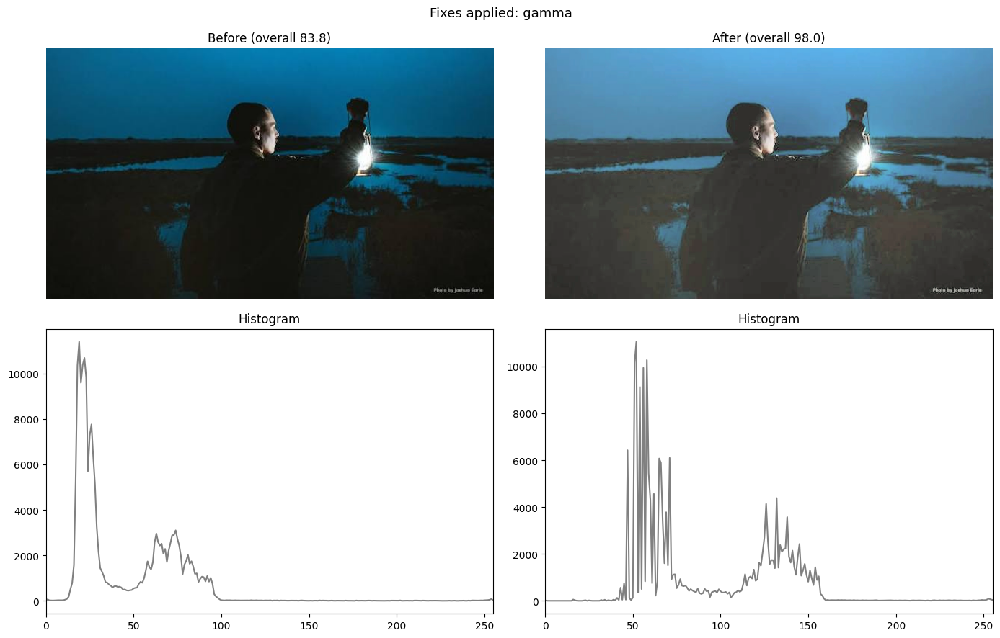


Saved files: {'fixed': 'output/test pic brightness_fixed.jpg', 'csv': 'output/test pic brightness_report.csv', 'report': 'output/test pic brightness_report.png'}


In [60]:
# What: runs the entry point on the photo you uploaded in step 1 and shows the report.
# Why: this is the first real end-to-end run, and the output files appear in the Colab file browser under the "output" folder.
result = process_photo(path)                              # "path" is the file you uploaded in step 1
print("\nSaved files:", result["files"])

Replay helpers: gamma max diff 0, stretch max diff 0, warp size diff 0,0, warp mean diff 0.06
test_damaged.jpg: 498x277 -> 498x277 | applied: ['gamma', 'nlm'] | overall 64.1 -> 93.3 (800 px run: 93.3) | 1.6s
        check                  before                  after       status                         action
   brightness             13.7 (dark)            58.0 (dark) fail -> fail                   fixed: gamma
     contrast     46.0 (low contrast)           128.0 (good)   fail -> ok                      not fixed
     clipping 48.62 (clipped shadows) 9.25 (clipped shadows) fail -> fail flagged only (cannot be fixed)
         blur           684.8 (sharp)         1304.3 (sharp)     ok -> ok                              -
        noise             3.6 (clean)           2.85 (clean)     ok -> ok                     fixed: nlm
         tilt          no clear lines         no clear lines     ok -> ok                              -
  perspective        no dominant quad       no dominant q

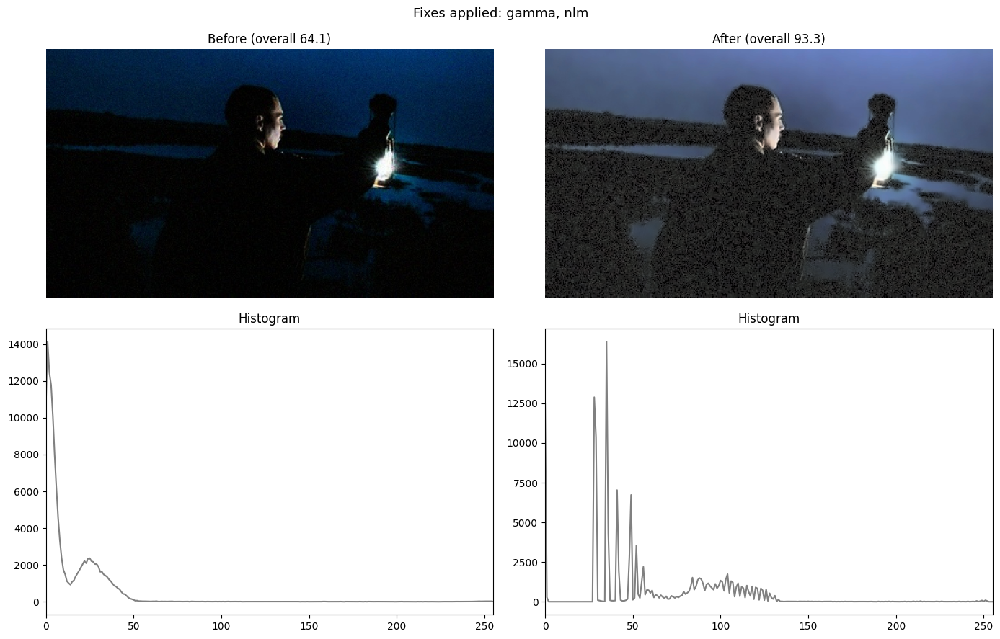

Log: ['gamma', 'nlm(h=8.1)'] | scale: 1.0
test pic brightness_fixed.jpg: 596x335 -> 596x335 | applied: nothing | overall 98.0 -> 98.0 (800 px run: 98.0) | 0.8s
Second pass applied: [] | output byte-identical to input: True


In [61]:
# What: checks the replay helpers against the original fix functions, runs a damaged full-size photo end to end, and runs the saved result through again.
# Why: the helper checks catch replay mistakes, the damaged photo proves the full-resolution path works, and the second run proves a fixed photo is left byte-identical.
def md5(p): return hashlib.md5(open(p, "rb").read()).hexdigest()
img = data["bgr"]; hh, ww = img.shape[:2]

# (a) replay helpers match the functions that produced the numbers
dark = cv2.LUT(img, (255 * (np.arange(256) / 255.0) ** 2.0).astype(np.uint8))
o1, p1 = fix_brightness(dark, "dark"); d_gamma = int(np.abs(o1.astype(int) - apply_gamma(dark, p1["gamma"]).astype(int)).max())
low = np.clip(128 + (img.astype(np.float32) - 128) * 0.4, 0, 255).astype(np.uint8)
o2, p2 = fix_stretch(low); d_stretch = int(np.abs(o2.astype(int) - apply_stretch(low, *p2["stretch_from"]).astype(int)).max())
quad = np.float32([[0.1 * ww, 0.1 * hh], [0.9 * ww, 0.05 * hh], [0.95 * ww, 0.9 * hh], [0.05 * ww, 0.85 * hh]])
o3, p3q = fix_perspective(img, quad); o4 = warp_quad(img, np.array(p3q["quad"], np.float32))
ch, cw = min(o3.shape[0], o4.shape[0]), min(o3.shape[1], o4.shape[1])
d_warp = float(np.abs(o3[:ch, :cw].astype(int) - o4[:ch, :cw].astype(int)).mean())
print(f"Replay helpers: gamma max diff {d_gamma}, stretch max diff {d_stretch}, warp size diff {abs(o3.shape[0]-o4.shape[0])},{abs(o3.shape[1]-o4.shape[1])}, warp mean diff {d_warp:.2f}")

# (b) a damaged full-size photo, end to end
original = load_image(path)
dam = add_noise(cv2.LUT(rotate_cw(original, 6), (255 * (np.arange(256) / 255.0) ** 2.0).astype(np.uint8)), 6)      # tilted, dark and noisy
cv2.imwrite("test_damaged.jpg", dam, [cv2.IMWRITE_JPEG_QUALITY, 95])
res_d = process_photo("test_damaged.jpg")
print("Log:", res_d["log"], "| scale:", round(res_d["scale"], 2))

# (c) run the saved result of your first photo through again
res_g = process_photo(result["files"]["fixed"], out_dir="output_second", show=False)
same = md5(result["files"]["fixed"]) == md5(res_g["files"]["fixed"])
print("Second pass applied:", res_g["applied"], "| output byte-identical to input:", same)

Replay helpers: gamma max diff 0, stretch max diff 0, warp size diff 0,0, warp mean diff 0.06
test_damaged.jpg: 498x277 -> 498x277 | applied: ['gamma', 'nlm'] | overall 64.1 -> 93.3 (800 px run: 93.3) | 1.7s
        check                  before                  after       status                         action
   brightness             13.7 (dark)            58.0 (dark) fail -> fail                   fixed: gamma
     contrast     46.0 (low contrast)           128.0 (good)   fail -> ok                      not fixed
     clipping 48.62 (clipped shadows) 9.25 (clipped shadows) fail -> fail flagged only (cannot be fixed)
         blur           684.8 (sharp)         1304.3 (sharp)     ok -> ok                              -
        noise             3.6 (clean)           2.85 (clean)     ok -> ok                     fixed: nlm
         tilt          no clear lines         no clear lines     ok -> ok                              -
  perspective        no dominant quad       no dominant q

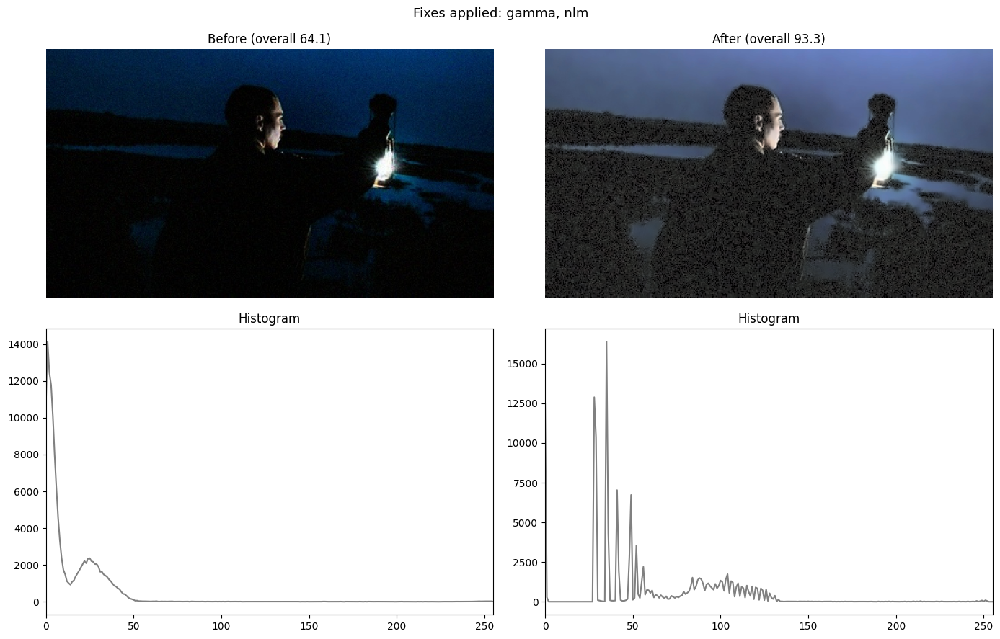

Log: ['gamma', 'nlm(h=8.1)'] | scale: 1.0
test pic brightness_fixed.jpg: 596x335 -> 596x335 | applied: nothing | overall 98.0 -> 98.0 (800 px run: 98.0) | 1.1s
Second pass applied: [] | output byte-identical to input: True


In [62]:
# What: checks the replay helpers against the original fix functions, runs a damaged full-size photo end to end, and runs the saved result through again.
# Why: the helper checks catch replay mistakes, the damaged photo proves the full-resolution path works, and the second run proves a fixed photo is left byte-identical.
def md5(p): return hashlib.md5(open(p, "rb").read()).hexdigest()
img = data["bgr"]; hh, ww = img.shape[:2]

# (a) replay helpers match the functions that produced the numbers
dark = cv2.LUT(img, (255 * (np.arange(256) / 255.0) ** 2.0).astype(np.uint8))
o1, p1 = fix_brightness(dark, "dark"); d_gamma = int(np.abs(o1.astype(int) - apply_gamma(dark, p1["gamma"]).astype(int)).max())
low = np.clip(128 + (img.astype(np.float32) - 128) * 0.4, 0, 255).astype(np.uint8)
o2, p2 = fix_stretch(low); d_stretch = int(np.abs(o2.astype(int) - apply_stretch(low, *p2["stretch_from"]).astype(int)).max())
quad = np.float32([[0.1 * ww, 0.1 * hh], [0.9 * ww, 0.05 * hh], [0.95 * ww, 0.9 * hh], [0.05 * ww, 0.85 * hh]])
o3, p3q = fix_perspective(img, quad); o4 = warp_quad(img, np.array(p3q["quad"], np.float32))
ch, cw = min(o3.shape[0], o4.shape[0]), min(o3.shape[1], o4.shape[1])
d_warp = float(np.abs(o3[:ch, :cw].astype(int) - o4[:ch, :cw].astype(int)).mean())
print(f"Replay helpers: gamma max diff {d_gamma}, stretch max diff {d_stretch}, warp size diff {abs(o3.shape[0]-o4.shape[0])},{abs(o3.shape[1]-o4.shape[1])}, warp mean diff {d_warp:.2f}")

# (b) a damaged full-size photo, end to end
original = load_image(path)
dam = add_noise(cv2.LUT(rotate_cw(original, 6), (255 * (np.arange(256) / 255.0) ** 2.0).astype(np.uint8)), 6)      # tilted, dark and noisy
cv2.imwrite("test_damaged.jpg", dam, [cv2.IMWRITE_JPEG_QUALITY, 95])
res_d = process_photo("test_damaged.jpg")
print("Log:", res_d["log"], "| scale:", round(res_d["scale"], 2))

# (c) run the saved result of your first photo through again
res_g = process_photo(result["files"]["fixed"], out_dir="output_second", show=False)
same = md5(result["files"]["fixed"]) == md5(res_g["files"]["fixed"])
print("Second pass applied:", res_g["applied"], "| output byte-identical to input:", same)

In [64]:
# What: uploads several photos at once into a folder named "photos" and lists them.
# Why: one folder lets every later cell process the whole set, and the originals are kept untouched.
os.makedirs("photos", exist_ok=True)
up = files.upload()                                              # select all your test photos in the dialog
for name, content in up.items():
    with open(os.path.join("photos", name), "wb") as f:
        f.write(content)
photos = sorted(f for f in os.listdir("photos") if f.lower().endswith((".jpg", ".jpeg", ".png")))
print(len(photos), "photos:", photos)

Saving test pic tilt.jpg to test pic tilt.jpg
1 photos: ['test pic tilt.jpg']


In [65]:
# What: prints an empty LABELS dictionary with one line per uploaded photo, ready to copy into the next cell.
# Why: you fill in what is really wrong with each photo, and that becomes the answer key the tool is scored against.
PROBLEMS = ["dark", "bright", "lowcontrast", "clipped", "blurry", "noisy", "tilted", "skewed"]
print("Allowed labels:", PROBLEMS, "\n")
print("LABELS = {")
for p in photos: print(f'    "{p}": [],')
print("}")

Allowed labels: ['dark', 'bright', 'lowcontrast', 'clipped', 'blurry', 'noisy', 'tilted', 'skewed'] 

LABELS = {
    "test pic tilt.jpg": [],
}


In [66]:
#labels and evaluation
# What: holds your labels, then runs the pipeline on the 800 px copy of every photo and tabulates what was flagged, what was fixed and the raw metrics.
# Why: this is the fast loop for tuning, because it skips the full-size replay and saves nothing.
LABELS = {
    # paste the dictionary printed above and fill it in, for example:
    # "kitchen.jpg": ["dark", "noisy"],
    # "park.jpg": [],               # an empty list means "this photo is fine"
}

CHECK_PROBLEM = {"contrast": "lowcontrast", "clipping": "clipped", "blur": "blurry", "noise": "noisy", "tilt": "tilted", "perspective": "skewed"}
FIXABLE = {"dark", "bright", "lowcontrast", "noisy", "tilted", "skewed"}      # blur and clipping are flagged only
def problem_of(n, c): return c["label"] if n == "brightness" else CHECK_PROBLEM[n]       # brightness reads "dark" or "bright"

work_cache = {f: prepare(load_image(os.path.join("photos", f)))["bgr"] for f in photos}   # 800 px copies, loaded once

def evaluate(labels):
    rows = []
    for f, work in work_cache.items():
        pipe = run_pipeline_v4(work)
        b = pipe["before"]["by_name"]
        names = ["brightness", *CHECK_PROBLEM]
        flagged = {problem_of(n, b[n]) for n in names if b[n]["status"] == "fail"}
        near = {problem_of(n, b[n]) for n in names if b[n]["status"] == "borderline"}
        if "median" in pipe["applied"] or "nlm" in pipe["applied"]: flagged.add("noisy")      # noise that only appears after brightening
        rows.append({"file": f, "labelled": sorted(labels[f]) if f in labels else None, "flagged": sorted(flagged),
                     "near miss": sorted(near - flagged), "applied": pipe["applied"],
                     "overall": f"{pipe['before']['overall']} -> {pipe['after']['overall']}",
                     "mean": b["brightness"]["value"], "range": b["contrast"]["value"], "clip": b["clipping"]["value"],
                     "sharp": b["blur"]["value"], "sigma": b["noise"]["value"], "tilt": abs(b["tilt"]["value"]),
                     "skew": b["perspective"]["value"], "tilt_conf": round(pipe["before"]["tilt"]["conf"], 2)})
    return pd.DataFrame(rows)

df = evaluate(LABELS)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print(df[["file", "labelled", "flagged", "near miss", "applied", "overall"]].to_string(index=False))
print("\nRaw metrics:")
print(df[["file", "mean", "range", "clip", "sharp", "sigma", "tilt", "tilt_conf", "skew"]].to_string(index=False))

             file labelled flagged near miss applied        overall
test pic tilt.jpg     None      []        []      [] 100.0 -> 100.0

Raw metrics:
             file  mean  range  clip   sharp  sigma  tilt  tilt_conf  skew
test pic tilt.jpg 112.2  204.0  1.02 12529.9    1.0  0.24       0.14   NaN


In [67]:
#score the agreement
# What: compares the tool's flags with your labels per problem, and lists good photos that were flagged or changed.
# Why: false alarms on good photos are the failure we care about most, so they are reported separately from missed problems.
def score(df):
    lab = df[df["labelled"].notna()]
    if lab.empty:
        print("No labels yet: fill in LABELS in cell 3 and re-run it."); return None
    rows = []
    for p in PROBLEMS:
        tp = [f for f, l, g in zip(lab["file"], lab["labelled"], lab["flagged"]) if p in l and p in g]
        fp = [f for f, l, g in zip(lab["file"], lab["labelled"], lab["flagged"]) if p not in l and p in g]
        fn = [f for f, l, g in zip(lab["file"], lab["labelled"], lab["flagged"]) if p in l and p not in g]
        if tp or fp or fn:
            rows.append({"problem": p, "found": len(tp), "false alarms": fp, "missed": fn})
    print(pd.DataFrame(rows).to_string(index=False))
    good = lab[lab["labelled"].apply(len) == 0]
    flagged_good = good[good["flagged"].apply(len) > 0]["file"].tolist()
    changed_good = good[good["applied"].apply(len) > 0]["file"].tolist()
    print(f"\nGood photos: {len(good)} | flagged: {flagged_good or 'none'} | changed: {changed_good or 'none'}")
    return lab

lab = score(df)

No labels yet: fill in LABELS in cell 3 and re-run it.


In [68]:
#suggest limits from photos
# What: for each problem, compares the metric of the photos you labelled with that problem against all other photos, and suggests a limit if the two groups do not overlap.
# Why: a limit should sit in the gap between problem photos and fine photos, and when the groups overlap, no limit can separate them and the metric itself needs work.
SPEC = {   # problem: (metric column, which side the problem is on, LIMITS key)
    "dark": ("mean", "low", "dark_mean"), "bright": ("mean", "high", "bright_mean"), "lowcontrast": ("range", "low", "contrast"),
    "blurry": ("sharp", "low", "blur"), "noisy": ("sigma", "high", "noise"), "tilted": ("tilt", "high", "tilt"),
    "skewed": ("skew", "high", "perspective"), "clipped": ("clip", "high", "clipping"),
}
APPLY = False                                         # set to True to write the suggestions into LIMITS, then re-run cells 3 and 4

def suggest_limits(df):
    lab = df[df["labelled"].notna()]
    out = {}
    for p, (col, side, key) in SPEC.items():
        has = lab["labelled"].apply(lambda l: p in l)
        prob, other = lab.loc[has, col].dropna(), lab.loc[~has, col].dropna()
        if len(prob) == 0 or len(other) == 0:
            continue                                  # needs both kinds of photo
        L, M = LIMITS[key]["limit"], LIMITS[key]["margin"]
        if side == "low":
            sep, edge = prob.max() < other.min(), (prob.max() + other.min()) / 2
            new, now_fails = edge + M, f"below {L - M:g}"        # fail starts at limit minus margin
        else:
            sep, edge = prob.min() > other.max(), (prob.min() + other.max()) / 2
            new, now_fails = edge - M, f"above {L + M:g}"        # fail starts at limit plus margin
        msg = f"{p:12s} problem photos {prob.min():.1f} to {prob.max():.1f} | other photos {other.min():.1f} to {other.max():.1f} | fails now: {now_fails}"
        print(msg + (f" -> suggested limit {new:.1f} (now {L:g})" if sep else " -> ranges overlap, no limit can separate them"))
        if sep: out[key] = round(float(new), 2)
    return out

sug = suggest_limits(df)
if APPLY:
    for k, v in sug.items(): LIMITS[k]["limit"] = v
    print("Applied:", sug)

test pic tilt.jpg: 508x603 -> 508x603 | applied: nothing | overall 100.0 -> 100.0 (800 px run: 100.0) | 1.4s

             file               size applied        overall  replay gap  sec
test pic tilt.jpg 508x603 -> 508x603      [] 100.0 -> 100.0         0.0  1.4


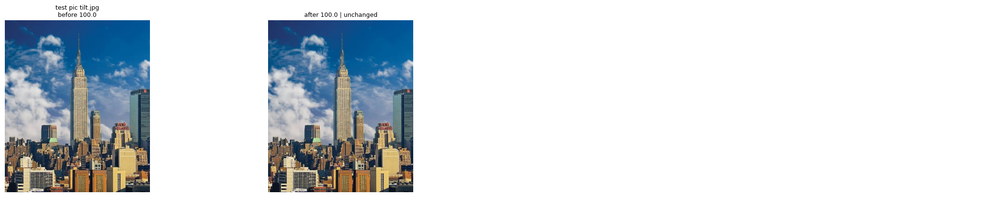

In [69]:
#full run with saved output
# What: runs the real entry point on every photo at full resolution, prints a summary table, and saves one before/after contact sheet.
# Why: this is the final test with the replayed full-size fixes, and the contact sheet lets you judge every result by eye in one view.
def process_folder(folder="photos", out_dir="output_batch"):
    rows, results = [], {}
    for f in sorted(os.listdir(folder)):
        if not f.lower().endswith((".jpg", ".jpeg", ".png")): continue
        r = process_photo(os.path.join(folder, f), out_dir=out_dir, show=False)
        results[f] = r
        rows.append({"file": f, "size": f"{r['orig_size'][0]}x{r['orig_size'][1]} -> {r['out_size'][0]}x{r['out_size'][1]}",
                     "applied": r["applied"], "overall": f"{r['pipe']['before']['overall']} -> {r['verified_overall']}",
                     "replay gap": round(abs(r["verified_overall"] - r["pipe"]["after"]["overall"]), 1), "sec": round(r["seconds"], 1)})
    return pd.DataFrame(rows), results

def contact_sheet(results, out_path):
    names = list(results); n = len(names); nrows = (n + 1) // 2
    fig, axes = plt.subplots(nrows, 4, figsize=(22, 4.2 * nrows)); axes = np.atleast_2d(axes)
    for ax in axes.flat: ax.axis("off")
    for i, f in enumerate(names):
        r = results[f]; row, col = i // 2, (i % 2) * 2
        before = prepare(load_image(r["path"]))["bgr"]; after = prepare(load_image(r["files"]["fixed"]))["bgr"]
        axes[row, col].imshow(cv2.cvtColor(before, cv2.COLOR_BGR2RGB)); axes[row, col].set_title(f"{f}\nbefore {r['pipe']['before']['overall']}", fontsize=9)
        axes[row, col + 1].imshow(cv2.cvtColor(after, cv2.COLOR_BGR2RGB))
        axes[row, col + 1].set_title(f"after {r['verified_overall']} | {', '.join(r['applied']) or 'unchanged'}", fontsize=9)
    plt.tight_layout(); fig.savefig(out_path, dpi=110, bbox_inches="tight"); plt.show()

summary, batch = process_folder()
print("\n" + summary.to_string(index=False))
contact_sheet(batch, "output_batch/contact_sheet.png")

In [70]:
#acceptance gates and final settings
# What: checks five pass/fail gates (no false alarms on good photos, most labelled problems found, no photo scoring lower, replay consistent, no crashes) and prints the settings.
# Why: step 9 is finished when the gates pass, and the printed settings are what step 10 will bake into the final notebook.
df = evaluate(LABELS)                                 # re-evaluate with the current limits
labd = df[df["labelled"].notna()]
good = labd[labd["labelled"].apply(len) == 0]
alarms = good[(good["applied"].apply(len) > 0)]["file"].tolist()
found = sum(len(set(l) & set(g)) for l, g in zip(labd["labelled"], labd["flagged"]))
total = sum(len(l) for l in labd["labelled"])
worse = [f for f, r in batch.items() if r["verified_overall"] < r["pipe"]["before"]["overall"]]
gaps = summary[summary["replay gap"] > 6]["file"].tolist()
gates = [
    ("labels provided", len(labd) >= 6, f"{len(labd)} labelled photos (need at least 6)"),
    ("good photos left alone", len(good) >= 2 and not alarms, f"{len(good)} good photos, changed: {alarms or 'none'}"),
    ("labelled problems found", total > 0 and found / max(total, 1) >= 0.8, f"{found} of {total} found"),
    ("no photo scores lower", not worse, f"lower: {worse or 'none'}"),
    ("replay matches 800 px run", not gaps, f"gap above 6: {gaps or 'none'}"),
]
print(pd.DataFrame([{"gate": g, "result": "PASS" if ok else "FAIL", "detail": d} for g, ok, d in gates]).to_string(index=False))
print("\nStep 9 gates passed" if all(ok for _, ok, _ in gates) else "\nSome gates failed: see the table above")
print("\nFinal settings to keep:")
print("LIMITS =", {k: v for k, v in LIMITS.items()}); print("TILT min_conf =", TILT["min_conf"], "| TARGET_MEAN =", TARGET_MEAN)

                     gate result                              detail
          labels provided   FAIL 0 labelled photos (need at least 6)
   good photos left alone   FAIL        0 good photos, changed: none
  labelled problems found   FAIL                        0 of 0 found
    no photo scores lower   PASS                         lower: none
replay matches 800 px run   PASS                   gap above 6: none

Some gates failed: see the table above

Final settings to keep:
LIMITS = {'dark_mean': {'limit': 80, 'margin': 10}, 'bright_mean': {'limit': 180, 'margin': 10}, 'contrast': {'limit': 120, 'margin': 15}, 'clipping': {'limit': 5.0, 'margin': 2.0}, 'blur': {'limit': 60, 'margin': 20}, 'noise': {'limit': 4.0, 'margin': 1.5}, 'tilt': {'limit': 0.5, 'margin': 0.5}, 'perspective': {'limit': 3.0, 'margin': 2.0}, 'distortion': {'limit': 0.5, 'margin': 0.5}}
TILT min_conf = 0.1 | TARGET_MEAN = {'dark': 100, 'bright': 150}
